# KDE bandwidth playground and spectral scale selection

This notebook is a small experimental environment for bandwidth selection in kernel density estimation. We sample

$$

X_1,\dots,X_n\sim \mathcal N(0,\sigma^2),

$$

and estimate the unknown density by the one-dimensional KDE

$$

\widehat{f}_h(x)=\frac{1}{nh}\sum_{r=1}^n K\left(\frac{x-X_r}{h}\right).

$$

The bandwidth $h>0$ is the scale parameter. Small $h$ produces rough, spiky estimates; large $h$ produces smooth, possibly oversmoothed estimates. The goal of the notebook is to compare several ways of selecting a representative scale from a grid

$$

h_1<\dots<h_N.

$$

The notebook contains four types of experiments:

1. direct KDE visualization for chosen $n$, $\sigma^2$, kernel, and bandwidth;
2. exact $L^2$ scale-similarity matrices for Gaussian and Epanechnikov kernels;
3. an oracle bandwidth computed from the known true density in the simulation;
4. an entropy/Jensen-Shannon similarity matrix whose principal eigenvector gives a spectral bandwidth choice.

Only two kernels are used here: Gaussian and Epanechnikov. The simulated data always come from $N(0,\sigma^2)$, and the $L^p$-based experiments are restricted to $p=2$.

The oracle bandwidth is only available in simulation, but it is useful as a benchmark for judging whether the spectral selectors behave sensibly.


In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib-cache"))

import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")


## 1. Kernel functions and KDE implementation

The first code block defines the two kernels used throughout the notebook: Gaussian and Epanechnikov. Each kernel $K$ is normalized so that

$$

\int_{\mathbb R} K(u)\,du=1.

$$

For bandwidth $h$, the rescaled kernel is

$$

K_h(x)=\frac{1}{h}K\left(\frac{x}{h}\right),

$$

and therefore the KDE can also be written as

$$

\widehat{f}_h(x)=\frac{1}{n}\sum_{r=1}^n K_h(x-X_r).

$$

In the code, `kde_eval(x_grid, samples, h, kernel)` evaluates this function on a finite numerical grid `x_grid`. The entropy/Jensen-Shannon parts use this grid. The $L^2$ Minkowski and oracle computations below use exact formulas instead of numerical quadrature.


In [2]:
AVAILABLE_KERNELS = [
    "gaussian",
    "epanechnikov",
]


def kernel_values(u, kernel="gaussian"):
    """Evaluate a normalized one-dimensional Gaussian or Epanechnikov kernel K(u)."""
    u = np.asarray(u)
    kernel = kernel.lower()

    if kernel == "gaussian":
        return np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)

    if kernel == "epanechnikov":
        out = np.zeros_like(u, dtype=float)
        inside = np.abs(u) <= 1
        out[inside] = 0.75 * (1 - u[inside] ** 2)
        return out

    raise ValueError(f"Unknown kernel: {kernel!r}. Choose one of {AVAILABLE_KERNELS}.")


def kde_eval(x_grid, samples, h, kernel="gaussian"):
    """Evaluate the KDE on x_grid for data samples and bandwidth h."""
    samples = np.asarray(samples)
    x_grid = np.asarray(x_grid)

    if h <= 0:
        raise ValueError("The bandwidth h must be positive.")
    if len(samples) == 0:
        raise ValueError("Need at least one sample point.")

    u = (x_grid[:, None] - samples[None, :]) / h
    return kernel_values(u, kernel=kernel).mean(axis=1) / h


def normal_pdf(x, sigma2):
    """True N(0, sigma^2) density."""
    sigma = np.sqrt(sigma2)
    return np.exp(-0.5 * (x / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))


## 2. Static KDE example

This block samples data once and computes one KDE for one manually chosen bandwidth. It is the simplest sanity check for the estimator.

The parameters are:

- `n`: number of sample points;
- `sigma2`: variance of the true normal distribution;
- `h`: KDE bandwidth;
- `kernel`: kernel shape;
- `seed`: random seed, so the experiment is reproducible.

The plot overlays the histogram, the KDE $\widehat{f}_h$, the true density $f$, and the sample locations. This lets you visually inspect whether the chosen bandwidth undersmooths or oversmooths.


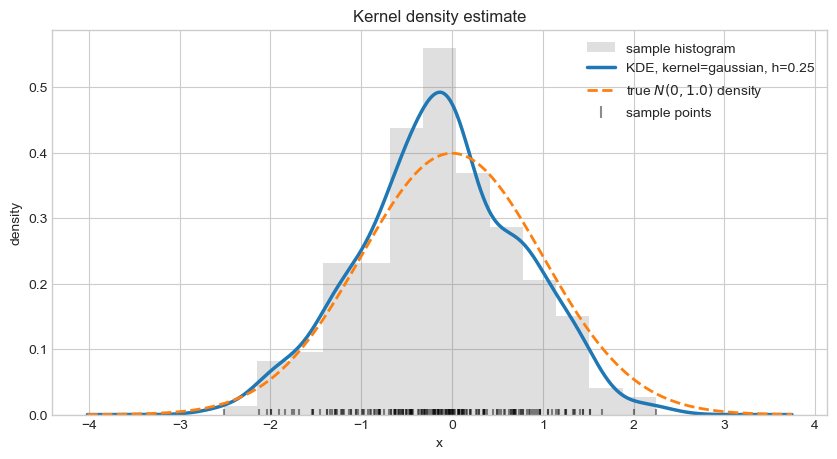

In [3]:
# Parameters you can change
n = 200
sigma2 = 1.0
h = 0.25
kernel = "gaussian"
seed = 7

rng = np.random.default_rng(seed)
X = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

x_min = X.min() - 4 * h - 0.5
x_max = X.max() + 4 * h + 0.5
x_grid = np.linspace(x_min, x_max, 800)

kde = kde_eval(x_grid, X, h=h, kernel=kernel)
truth = normal_pdf(x_grid, sigma2=sigma2)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(X, bins="auto", density=True, alpha=0.25, color="gray", label="sample histogram")
ax.plot(x_grid, kde, lw=2.5, label=f"KDE, kernel={kernel}, h={h}")
ax.plot(x_grid, truth, "--", lw=2, label=fr"true $N(0,{sigma2})$ density")
ax.scatter(X, np.zeros_like(X), marker="|", s=80, color="black", alpha=0.45, label="sample points")
ax.set_title("Kernel density estimate")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()


## 3. Compare several bandwidths

Here we hold the data set fixed and evaluate several KDEs

$$

\widehat{f}_{h_1},\widehat{f}_{h_2},\dots

$$

on the same grid. This isolates the effect of the bandwidth from the randomness of the sample.

The qualitative behavior should be:

- small $h$: many narrow peaks, high variance, low bias;
- large $h$: one broad smooth curve, low variance, high bias;
- intermediate $h$: often the best compromise.

This is the visual intuition behind bandwidth selection.


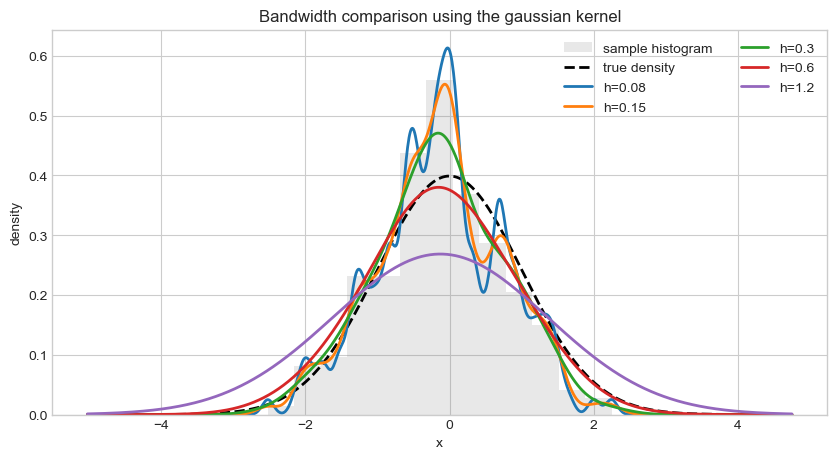

In [4]:
n = 200
sigma2 = 1.0
kernel = "gaussian"
bandwidths = [0.08, 0.15, 0.30, 0.60, 1.20]
seed = 7

rng = np.random.default_rng(seed)
X = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)
x_grid = np.linspace(X.min() - 2.5, X.max() + 2.5, 1000)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(X, bins="auto", density=True, alpha=0.18, color="gray", label="sample histogram")
ax.plot(x_grid, normal_pdf(x_grid, sigma2=sigma2), "k--", lw=2, label="true density")

for h_value in bandwidths:
    kde = kde_eval(x_grid, X, h=h_value, kernel=kernel)
    ax.plot(x_grid, kde, lw=2, label=f"h={h_value:g}")

ax.set_title(f"Bandwidth comparison using the {kernel} kernel")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend(ncol=2)
plt.show()


## 4. Interactive KDE plot

This section repeats the static KDE experiment with sliders. The most important control is the bandwidth slider $h$. Moving it shows the scale-space behavior of the KDE in real time.

Mathematically, changing $h$ changes the amount of smoothing in

$$

\widehat{f}_h(x)=\frac{1}{nh}\sum_{r=1}^nK\left(\frac{x-X_r}{h}\right).

$$

The sample itself changes only when `seed`, `n`, or `sigma²` changes. If `ipywidgets` is unavailable, the rest of the notebook still works; only this interactive control block is skipped.


In [5]:
try:
    from ipywidgets import Button, Dropdown, FloatLogSlider, HBox, IntSlider, Output, VBox
    from IPython.display import display
    widgets_available = True
except ModuleNotFoundError:
    widgets_available = False
    print(
        "ipywidgets is not installed in this Python environment. "
        "Install it with `pip install ipywidgets` or `conda install ipywidgets` "
        "to use the interactive sliders. The non-interactive KDE and matrix cells still work."
    )


if widgets_available:
    n_slider = IntSlider(value=200, min=20, max=2000, step=20, description="n")
    sigma2_slider = FloatLogSlider(
        value=1.0,
        base=10,
        min=-2,
        max=1.3,
        step=0.05,
        description="sigma²",
        readout_format=".3g",
    )
    seed_slider = IntSlider(value=7, min=0, max=999, step=1, description="seed")
    kernel_dropdown = Dropdown(options=AVAILABLE_KERNELS, value="gaussian", description="kernel")
    h_slider = FloatLogSlider(
        value=0.25,
        base=10,
        min=-2,
        max=1.1,
        step=0.01,
        description="h",
        readout_format=".3g",
        continuous_update=True,
    )
    resample_button = Button(description="resample", button_style="")
    out = Output()

    def draw_interactive_kde(*_):
        n = n_slider.value
        sigma2 = sigma2_slider.value
        seed = seed_slider.value
        h = h_slider.value
        kernel = kernel_dropdown.value

        rng = np.random.default_rng(seed)
        X = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n)

        # Use a plotting window that adapts to both the data spread and the current bandwidth.
        margin = max(4 * np.sqrt(sigma2), 6 * h, 1.0)
        x_grid = np.linspace(X.min() - margin, X.max() + margin, 1000)
        kde = kde_eval(x_grid, X, h=h, kernel=kernel)
        truth = normal_pdf(x_grid, sigma2=sigma2)

        with out:
            out.clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(10, 5.5))
            ax.hist(X, bins="auto", density=True, alpha=0.20, color="gray", label="sample histogram")
            ax.plot(x_grid, kde, lw=2.5, color="tab:blue", label=f"KDE, h={h:.3g}")
            ax.plot(x_grid, truth, "--", lw=2, color="black", label=fr"true $N(0,{sigma2:.3g})$ density")
            ax.scatter(X, np.zeros_like(X), marker="|", s=65, color="black", alpha=0.35)
            ax.set_title(f"Interactive KDE — {kernel} kernel, n={n}, sigma²={sigma2:.3g}")
            ax.set_xlabel("x")
            ax.set_ylabel("density")
            ax.legend(loc="upper right")
            plt.show()

    def advance_seed(_):
        seed_slider.value = seed_slider.value + 1 if seed_slider.value < seed_slider.max else seed_slider.min

    for widget in [n_slider, sigma2_slider, seed_slider, kernel_dropdown, h_slider]:
        widget.observe(draw_interactive_kde, names="value")

    resample_button.on_click(advance_seed)

    top_controls = HBox([n_slider, sigma2_slider])
    middle_controls = HBox([kernel_dropdown, seed_slider, resample_button])

    display(VBox([top_controls, middle_controls, out, h_slider]))
    draw_interactive_kde()


## 5. Shared simulation setup and exact helper formulas

From here on the notebook uses one common simulated sample

$$
X_1,\dots,X_n\sim N(0,\sigma^2),
$$

a bandwidth grid

$$
h_1<\cdots<h_N,
$$

and a family of KDEs

$$
\widehat f_{h_1},\dots,\widehat f_{h_N}.
$$

This block also defines exact one-dimensional $L^2$ formulas for Gaussian and Epanechnikov kernels. These formulas are used by the oracle bandwidth and by the $D_2^{(+)}$ and $D_2^{(-)}$ constructions.


In [6]:
# Shared state used by the spectral-scale-selection cells below.
# This cell intentionally rebuilds all variables that later plotting cells expect.
n_scale = 200
sigma2 = 1.0
kernel = "gaussian"  # choose "gaussian" or "epanechnikov"
seed_scale = 123
n_h = 80

rng = np.random.default_rng(seed_scale)
X = rng.normal(loc=0.0, scale=np.sqrt(sigma2), size=n_scale)

# The grid is centered around the usual n^{-1/5} bandwidth scale, but spans
# substantially smaller and larger bandwidths.
h_center = np.sqrt(sigma2) * n_scale ** (-1 / 5)
h_grid = np.geomspace(0.20 * h_center, 3.00 * h_center, n_h)

x_margin = 6.0 * (np.sqrt(sigma2) + np.max(h_grid))
x_grid = np.linspace(X.min() - x_margin, X.max() + x_margin, 2_001)

kde_family = np.array([
    kde_eval(x_grid, X, h=h_value, kernel=kernel)
    for h_value in h_grid
])
truth = normal_pdf(x_grid, sigma2=sigma2)


def trapz_integral(values, x=x_grid, axis=-1):
    """Compatibility wrapper for the trapezoidal rule."""
    trapz = getattr(np, "trapezoid", np.trapz)
    return trapz(values, x=x, axis=axis)


def principal_eigenvector_nonnegative(matrix):
    """Principal eigenvector of a symmetric nonnegative matrix, normalized to sum one."""
    matrix = np.asarray(matrix, dtype=float)
    eigenvalues, eigenvectors = np.linalg.eigh((matrix + matrix.T) / 2)
    vector = np.real(eigenvectors[:, int(np.argmax(eigenvalues))])
    if np.sum(vector) < 0:
        vector = -vector
    vector = np.maximum(vector, 0.0)
    if np.sum(vector) == 0:
        vector = np.abs(np.real(eigenvectors[:, int(np.argmax(eigenvalues))]))
    return vector / np.sum(vector)


# Oracle benchmark: numerical integrated squared error against the known N(0, sigma^2) density.
ise_values = trapz_integral((kde_family - truth[None, :]) ** 2, axis=1)
oracle_index = int(np.argmin(ise_values))
oracle_h = float(h_grid[oracle_index])

# Quadrature Gram matrix for the KDE family: G_ij = <f_i, f_j>_2.
l2_gram = trapz_integral(kde_family[:, None, :] * kde_family[None, :, :], axis=2)
lp_values = np.sqrt(np.maximum(np.diag(l2_gram), 0.0))

# D_2^(+) Minkowski triangle-defect similarity.
sum_norms = np.sqrt(
    np.maximum(
        np.diag(l2_gram)[:, None] + np.diag(l2_gram)[None, :] + 2.0 * l2_gram,
        0.0,
    )
)
D_plus_2 = lp_values[:, None] + lp_values[None, :] - sum_norms
D_plus_2 = np.maximum((D_plus_2 + D_plus_2.T) / 2, 0.0)

perron_vector = principal_eigenvector_nonnegative(D_plus_2)
selected_index = int(np.argmax(perron_vector))
selected_h = float(h_grid[selected_index])

print("Shared KDE state rebuilt")
print(f"sample size n = {n_scale}")
print(f"kernel = {kernel}")
print(f"oracle h = {oracle_h:.6g}")
print(f"D_plus_2 spectral h = {selected_h:.6g}")


Shared KDE state rebuilt
sample size n = 200
kernel = gaussian
oracle h = 0.523806
D_plus_2 spectral h = 1.03972


## 6. Oracle bandwidth from the known true density

Because the data in this notebook are simulated from a known density

$$
f(x)=N(0,\sigma^2),
$$

we can compute an oracle benchmark. For every candidate bandwidth, we evaluate

$$
ISE(h)=\int(\widehat f_h(x)-f(x))^2\,dx.
$$

The oracle bandwidth is

$$
h_{oracle}=\arg\min_{h_i} ISE(h_i).
$$

This is not available for real data; it is only a benchmark for the other selectors.


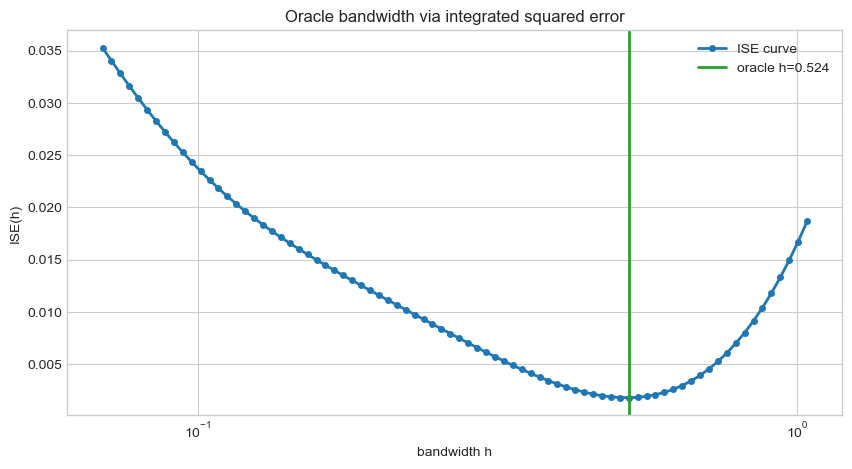

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h_grid, ise_values, marker="o", ms=4, lw=2, label="ISE curve")
ax.axvline(oracle_h, color="tab:green", ls="-", lw=2, label=f"oracle h={oracle_h:.3g}")
ax.set_xscale("log")
ax.set_title("Oracle bandwidth via integrated squared error")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("ISE(h)")
ax.legend()
plt.show()


## 7. $D^{(+)}_2$: Minkowski triangle-defect similarity

For $p=2$, define

$$
D^{(+)}_{2,ij}
=
\|\widehat f_i\|_2+\|\widehat f_j\|_2
-
\|\widehat f_i+\widehat f_j\|_2.
$$

This follows the triangle inequality and is nonnegative. In the notebook the required $L^2$ norms and inner products are computed exactly for the Gaussian and Epanechnikov kernels.


## 8. Plot $D^{(+)}_2$: scale functional, Perron vector, and matrix

The first panel shows the exact scale profile

$$
h_i\mapsto \|\widehat f_{h_i}\|_2.
$$

The second panel shows the Perron vector of $D^{(+)}_2$, and the third panel shows the matrix.


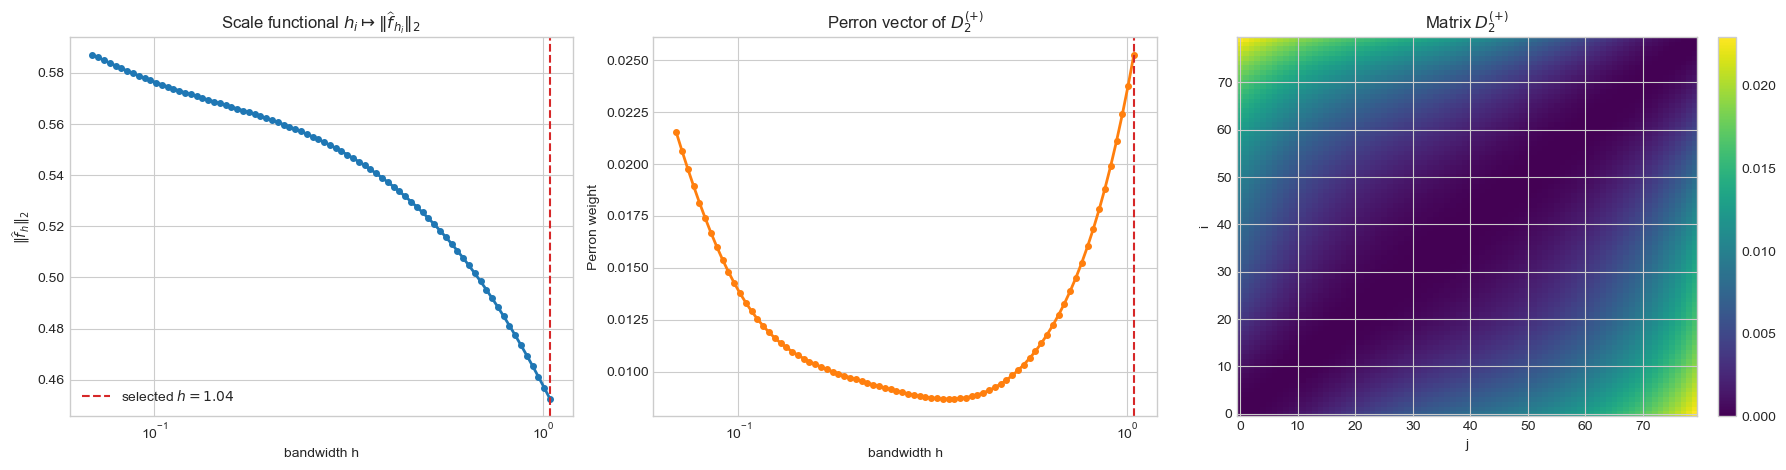

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(h_grid, lp_values, marker="o", ms=4, lw=2)
axes[0].axvline(selected_h, color="tab:red", ls="--", label=fr"selected $h={selected_h:.3g}$")
axes[0].set_xscale("log")
axes[0].set_title(r"Scale functional $h_i\mapsto \|\widehat f_{h_i}\|_2$")
axes[0].set_xlabel("bandwidth h")
axes[0].set_ylabel(r"$\|\widehat f_h\|_2$")
axes[0].legend()

axes[1].plot(h_grid, perron_vector, marker="o", ms=4, lw=2, color="tab:orange")
axes[1].axvline(selected_h, color="tab:red", ls="--")
axes[1].set_xscale("log")
axes[1].set_title(r"Perron vector of $D^{(+)}_2$")
axes[1].set_xlabel("bandwidth h")
axes[1].set_ylabel("Perron weight")

image = axes[2].imshow(D_plus_2, origin="lower", aspect="auto", cmap="viridis")
axes[2].set_title(r"Matrix $D^{(+)}_2$")
axes[2].set_xlabel("j")
axes[2].set_ylabel("i")
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


## 8b. Inspect the KDE selected by $D^{(+)}_2$


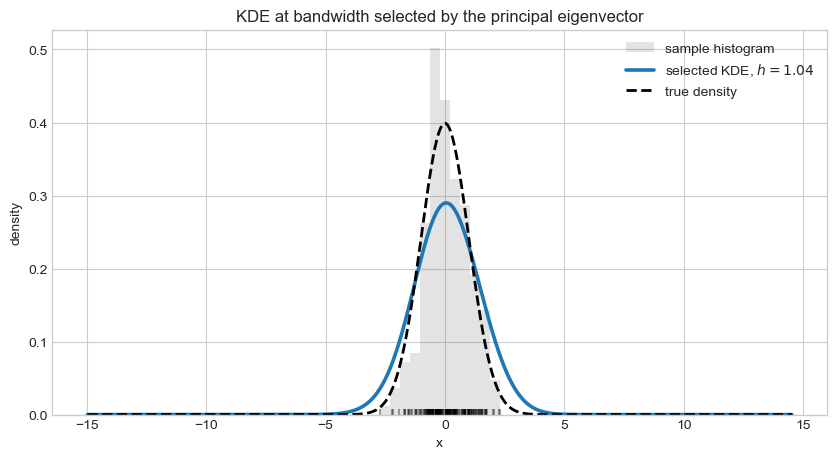

In [9]:
selected_kde = kde_family[selected_index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(X, bins="auto", density=True, alpha=0.22, color="gray", label="sample histogram")
ax.plot(x_grid, selected_kde, lw=2.6, color="tab:blue", label=fr"selected KDE, $h={selected_h:.3g}$")
ax.plot(x_grid, normal_pdf(x_grid, sigma2=sigma2), "--", lw=2, color="black", label="true density")
ax.scatter(X, np.zeros_like(X), marker="|", s=65, color="black", alpha=0.35)
ax.set_title("KDE at bandwidth selected by the principal eigenvector")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()


## 8c. Embedded birth-death stationary distribution from the monotone $L^2$ profile

This optional diagnostic uses the monotone profile $h\mapsto \|\widehat f_h\|_2$ and builds the embedded birth-death stationary distribution considered earlier in the scale-selection work.


Is h -> ||f_hat_h||_2 decreasing on the grid? True
Birth-death stationary distribution minimum at index 79, h = 1.03972
Minimum pi_BD value: 0.00173621


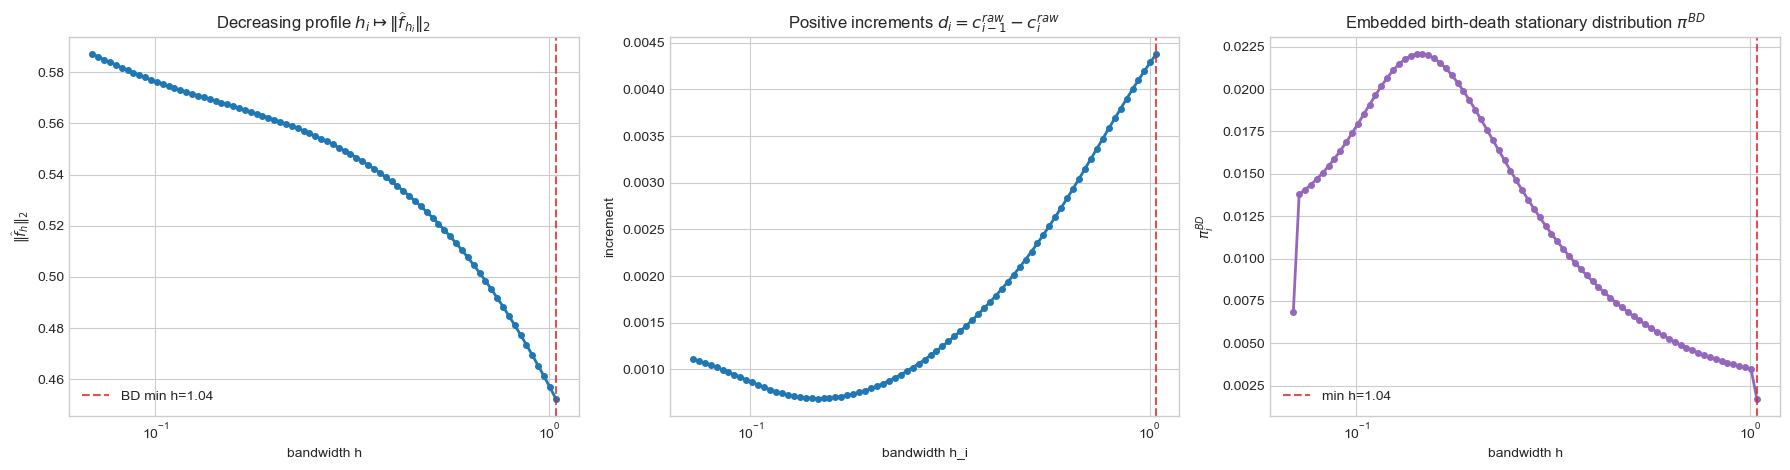

In [10]:
def birth_death_stationary_from_decreasing_profile(profile, eps=1e-12):
    """
    Embedded birth-death stationary distribution for a decreasing scale profile.

    If profile_i is decreasing, use c_i = profile_0 - profile_i as the increasing
    monotone profile. The increments are d_i = profile_{i-1} - profile_i.
    """
    profile = np.asarray(profile, dtype=float)
    increments = profile[:-1] - profile[1:]

    # Protect against tiny numerical non-monotonicity or flat increments.
    increments_safe = np.maximum(increments, eps)

    r = np.empty_like(profile)
    r[0] = 1.0 / increments_safe[0]
    r[-1] = 1.0 / increments_safe[-1]
    if len(profile) > 2:
        r[1:-1] = 1.0 / increments_safe[:-1] + 1.0 / increments_safe[1:]

    pi_bd = r / np.sum(r)
    return pi_bd, increments, increments_safe


bd_profile_raw = lp_values  # this is ||f_hat_h||_2 from the exact L2 Gram matrix
bd_is_decreasing = np.all(np.diff(bd_profile_raw) <= 1e-10)
pi_bd, bd_increments, bd_increments_safe = birth_death_stationary_from_decreasing_profile(bd_profile_raw)

bd_selected_index = int(np.argmin(pi_bd))
bd_selected_h = h_grid[bd_selected_index]

print(f"Is h -> ||f_hat_h||_2 decreasing on the grid? {bd_is_decreasing}")
print(f"Birth-death stationary distribution minimum at index {bd_selected_index}, h = {bd_selected_h:.6g}")
print(f"Minimum pi_BD value: {pi_bd[bd_selected_index]:.6g}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].plot(h_grid, bd_profile_raw, marker="o", ms=4, lw=2)
axes[0].axvline(bd_selected_h, color="tab:red", ls="--", alpha=0.8, label=f"BD min h={bd_selected_h:.3g}")
axes[0].set_xscale("log")
axes[0].set_title(r"Decreasing profile $h_i \mapsto \|\widehat{f}_{h_i}\|_2$")
axes[0].set_xlabel("bandwidth h")
axes[0].set_ylabel(r"$\|\widehat{f}_h\|_2$")
axes[0].legend()

axes[1].plot(h_grid[1:], bd_increments, marker="o", ms=4, lw=2, color="tab:blue")
axes[1].axvline(bd_selected_h, color="tab:red", ls="--", alpha=0.8)
axes[1].set_xscale("log")
axes[1].set_title(r"Positive increments $d_i=c^{raw}_{i-1}-c^{raw}_i$")
axes[1].set_xlabel("bandwidth h_i")
axes[1].set_ylabel("increment")

axes[2].plot(h_grid, pi_bd, marker="o", ms=4, lw=2, color="tab:purple")
axes[2].axvline(bd_selected_h, color="tab:red", ls="--", alpha=0.8, label=f"min h={bd_selected_h:.3g}")
axes[2].set_xscale("log")
axes[2].set_title(r"Embedded birth-death stationary distribution $\pi^{BD}$")
axes[2].set_xlabel("bandwidth h")
axes[2].set_ylabel(r"$\pi^{BD}_i$")
axes[2].legend()

plt.tight_layout()
plt.show()


## 9. $D^{(-)}_2$: distance-defect similarity

The minus construction is

$$
D^{(-)}_{2,ij}
=
\|\widehat f_i\|_2+\|\widehat f_j\|_2
-
\|\widehat f_i-\widehat f_j\|_2.
$$

Again, all $L^2$ quantities are computed from the exact Gram matrix.


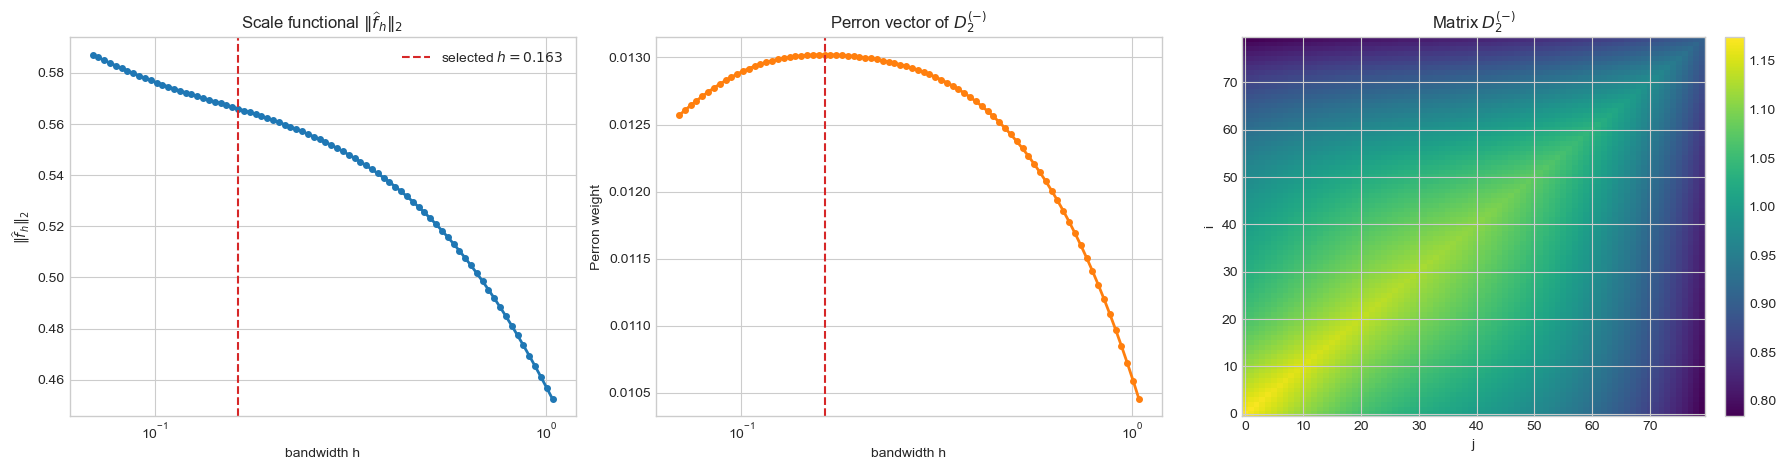

D_minus_2 selected h = 0.163307


In [11]:
# D_2^(-): distance-defect similarity based on the L2 distance.
# This is the version
# ||f_i||_2 + ||f_j||_2 - ||f_i - f_j||_2.
l2_distance = np.sqrt(
    np.maximum(
        np.diag(l2_gram)[:, None] + np.diag(l2_gram)[None, :] - 2.0 * l2_gram,
        0.0,
    )
)
D_minus_2 = lp_values[:, None] + lp_values[None, :] - l2_distance
D_minus_2 = np.maximum((D_minus_2 + D_minus_2.T) / 2, 0.0)

perron_minus = principal_eigenvector_nonnegative(D_minus_2)
selected_index_minus = int(np.argmax(perron_minus))
selected_h_minus = float(h_grid[selected_index_minus])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(h_grid, lp_values, marker="o", ms=4, lw=2)
axes[0].axvline(selected_h_minus, color="tab:red", ls="--", label=fr"selected $h={selected_h_minus:.3g}$")
axes[0].set_xscale("log")
axes[0].set_title(r"Scale functional $\|\widehat f_h\|_2$")
axes[0].set_xlabel("bandwidth h")
axes[0].set_ylabel(r"$\|\widehat f_h\|_2$")
axes[0].legend()

axes[1].plot(h_grid, perron_minus, marker="o", ms=4, lw=2, color="tab:orange")
axes[1].axvline(selected_h_minus, color="tab:red", ls="--")
axes[1].set_xscale("log")
axes[1].set_title(r"Perron vector of $D^{(-)}_2$")
axes[1].set_xlabel("bandwidth h")
axes[1].set_ylabel("Perron weight")

image = axes[2].imshow(D_minus_2, origin="lower", aspect="auto", cmap="viridis")
axes[2].set_title(r"Matrix $D^{(-)}_2$")
axes[2].set_xlabel("j")
axes[2].set_ylabel("i")
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f"D_minus_2 selected h = {selected_h_minus:.6g}")


## 9b. Inspect the KDE selected by $D^{(-)}_2$


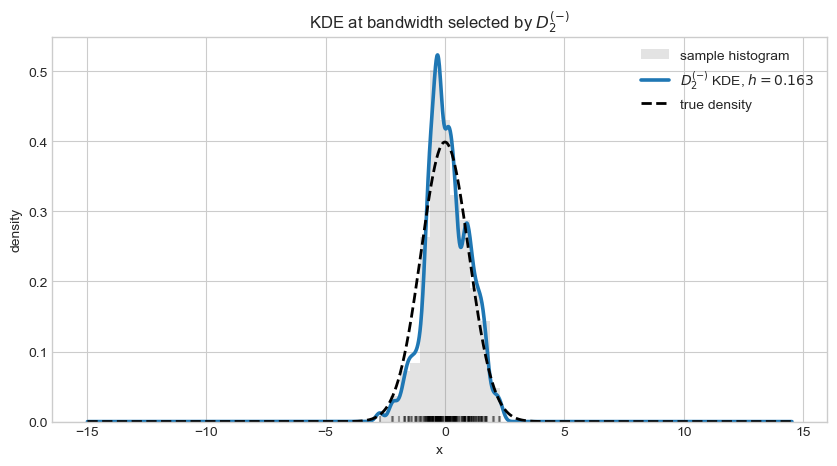

In [12]:
selected_kde_minus = kde_family[selected_index_minus]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(X, bins="auto", density=True, alpha=0.22, color="gray", label="sample histogram")
ax.plot(x_grid, selected_kde_minus, lw=2.6, color="tab:blue", label=fr"$D^{{(-)}}_2$ KDE, $h={selected_h_minus:.3g}$")
ax.plot(x_grid, truth, "--", lw=2, color="black", label="true density")
ax.scatter(X, np.zeros_like(X), marker="|", s=65, color="black", alpha=0.35)
ax.set_title(r"KDE at bandwidth selected by $D^{(-)}_2$")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()


## 10. $D^{\max}_p$: idempotent max/overlap similarity for general $p$

The idempotent construction does not have to be restricted to $p=2$. For any exponent $p>0$, define

$$
F_p(g):=\int g(x)^p\,dx.
$$

For two nonnegative functions, keep the pointwise join

$$
g\vee h := \max(g,h).
$$

The raw max-similarity matrix is

$$
D^{\max,p}_{ij}
:=F_p(\widehat f_i)+F_p(\widehat f_j)-F_p(\widehat f_i\vee \widehat f_j).
$$

Because the KDEs are nonnegative,

$$
(\widehat f_i\vee \widehat f_j)(x)^p
=\max\{\widehat f_i(x)^p,\widehat f_j(x)^p\}.
$$

Therefore the matrix entry simplifies to the overlap integral

$$
D^{\max,p}_{ij}
=\int \min\{\widehat f_i(x)^p,\widehat f_j(x)^p\}\,dx.
$$

Equivalently,

$$
D^{\max,p}_{ij}
=\int \min\{\widehat f_i(x),\widehat f_j(x)\}^p\,dx.
$$

The diagonal of the raw matrix is

$$
D^{\max,p}_{ii}=F_p(\widehat f_i)=\int \widehat f_i(x)^p\,dx.
$$

So the raw construction still has the idempotent self-similarity property: comparing a KDE with itself gives exactly its scale functional value.

### Optional normalization

Sometimes it is useful to remove the different diagonal scales and use a correlation-type overlap matrix. The normalized version is

$$
\Sigma^{\max,p}_{ij}
:=
\frac{D^{\max,p}_{ij}}
{\sqrt{F_p(\widehat f_i)F_p(\widehat f_j)}}.
$$

This gives

$$
\Sigma^{\max,p}_{ii}=1.
$$

In the code cell below, set

```python
normalize_join = True
```

to use the normalized matrix for the Perron eigenvector. Set

```python
normalize_join = False
```

to use the raw matrix $D^{\max,p}$. The notebook keeps both objects: `D_join_raw` is always the raw overlap matrix, and `D_join` is the matrix actually used for the eigenvector.

### Monte Carlo approximation using a global KDE-mixture proposal

Instead of sampling separately for every pair $(i,j)$, we use one common proposal density

$$
q(x)=\frac1N\sum_{r=1}^N \widehat f_r(x).
$$

This proposal is data-driven: it is built only from the KDE family itself and does not use the true simulation density. It can be sampled from directly:

1. choose a bandwidth index $R$ uniformly from $\{1,\dots,N\}$;
2. choose a data point $X_I$ uniformly from the sample;
3. draw $U$ from the selected base kernel;
4. set $Y=X_I+h_R U$.

For the Gaussian kernel, $U\sim N(0,1)$. For the Epanechnikov kernel, $U$ has density

$$
K(u)=\frac34(1-u^2)\mathbf 1_{[-1,1]}(u).
$$

Now draw

$$
Y_1,\dots,Y_M\sim q.
$$

Evaluate every KDE at every Monte Carlo point and store

$$
V_{mr}:=\widehat f_r(Y_m).
$$

Then

$$
q(Y_m)=\frac1N\sum_{r=1}^N V_{mr}.
$$

The raw max-overlap entry is estimated by

$$
D^{\max,p}_{ij}
\approx
\frac1M\sum_{m=1}^M
\frac{\min\{V_{mi},V_{mj}\}^p}{q(Y_m)}.
$$

The diagonal functional values are estimated by

$$
F_p(\widehat f_i)
\approx
\frac1M\sum_{m=1}^M
\frac{V_{mi}^p}{q(Y_m)}.
$$

If `normalize_join = True`, the code first computes the raw matrix and then divides each entry by

$$
\sqrt{F_p(\widehat f_i)F_p(\widehat f_j)}.
$$

The exponent is controlled by `p_join` below. The default `p_join = 2.0` reproduces the earlier $D^{\max}_2$ experiment, while values such as `1.5`, `3.0`, or `4.0` let you test how the selected scale changes with $p$.


In [13]:
# Monte Carlo/quadrature implementation of the idempotent max-overlap construction.
p_join = 2.0
normalize_join = False

Fp_values = trapz_integral(kde_family ** p_join, axis=1)
join_values = trapz_integral(np.maximum(kde_family[:, None, :], kde_family[None, :, :]) ** p_join, axis=2)
D_max_p = Fp_values[:, None] + Fp_values[None, :] - join_values
D_max_p = np.maximum((D_max_p + D_max_p.T) / 2, 0.0)

if normalize_join:
    denom = np.sqrt(np.maximum(np.outer(np.diag(D_max_p), np.diag(D_max_p)), 1e-300))
    Sigma_max_p = D_max_p / denom
    np.fill_diagonal(Sigma_max_p, 1.0)
    matrix_max_p = Sigma_max_p
else:
    Sigma_max_p = None
    matrix_max_p = D_max_p

perron_max_p = principal_eigenvector_nonnegative(matrix_max_p)
selected_index_max_p = int(np.argmax(perron_max_p))
selected_h_max_p = float(h_grid[selected_index_max_p])

print(f"p_join = {p_join}")
print(f"normalize_join = {normalize_join}")
print(f"D_max_p selected h = {selected_h_max_p:.6g}")


p_join = 2.0
normalize_join = False
D_max_p selected h = 0.152486


## 10b. Plot $D^{\max,p}$ or $\Sigma^{\max,p}$: functional, Perron vector, and matrix

This section visualizes the Monte Carlo idempotent max construction for the currently chosen value of `p_join`.

The first panel plots the raw diagonal functional

$$
h_i\mapsto F_p(\widehat f_i)=\int \widehat f_i(x)^p\,dx.
$$

The second panel plots the principal eigenvector of the matrix actually used for selection. If `normalize_join = False`, this matrix is the raw overlap matrix

$$
D^{\max,p}_{ij}
=\int \min\{\widehat f_i(x),\widehat f_j(x)\}^p\,dx.
$$

If `normalize_join = True`, the matrix is instead

$$
\Sigma^{\max,p}_{ij}
=\frac{D^{\max,p}_{ij}}
{\sqrt{F_p(\widehat f_i)F_p(\widehat f_j)}}.
$$

The third panel shows whichever of these two matrices is currently used. The entries are estimated using the global KDE-mixture proposal

$$
q(x)=\frac1N\sum_{r=1}^N\widehat f_r(x),
$$

not from the true Gaussian density. This means the matrix construction itself is based only on the data and the candidate bandwidth grid.


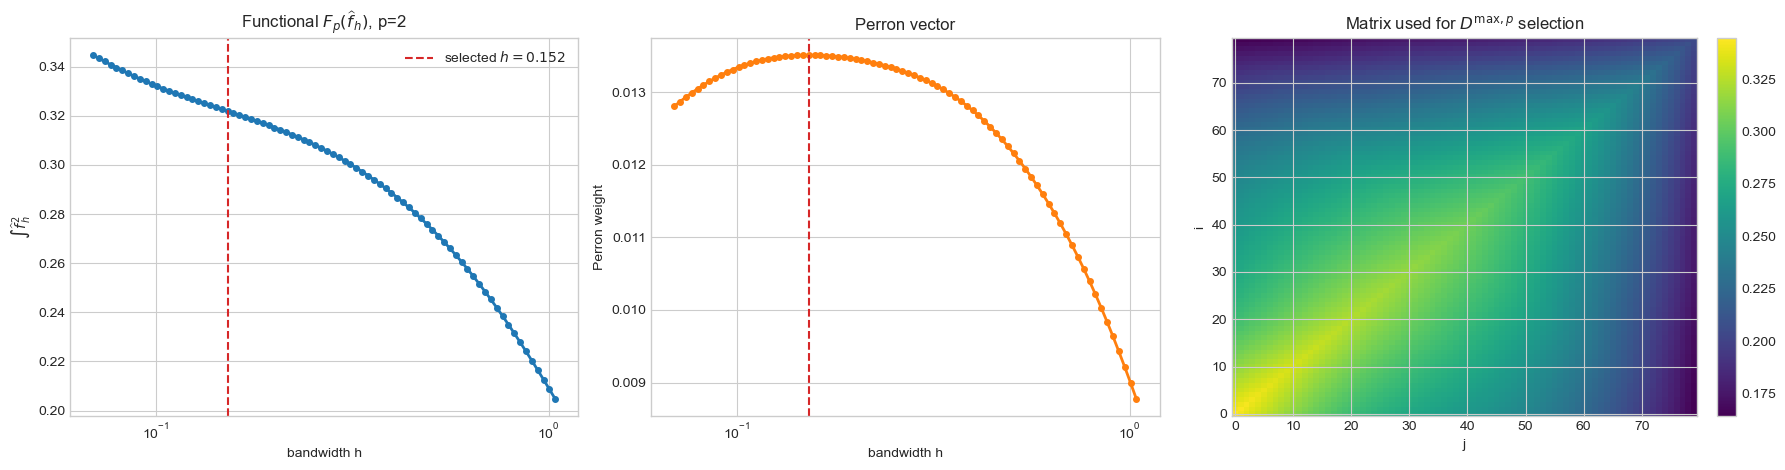

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(h_grid, Fp_values, marker="o", ms=4, lw=2)
axes[0].axvline(selected_h_max_p, color="tab:red", ls="--", label=fr"selected $h={selected_h_max_p:.3g}$")
axes[0].set_xscale("log")
axes[0].set_title(fr"Functional $F_p(\widehat f_h)$, p={p_join:g}")
axes[0].set_xlabel("bandwidth h")
axes[0].set_ylabel(fr"$\int \widehat f_h^{p_join:g}$")
axes[0].legend()

axes[1].plot(h_grid, perron_max_p, marker="o", ms=4, lw=2, color="tab:orange")
axes[1].axvline(selected_h_max_p, color="tab:red", ls="--")
axes[1].set_xscale("log")
axes[1].set_title("Perron vector")
axes[1].set_xlabel("bandwidth h")
axes[1].set_ylabel("Perron weight")

image = axes[2].imshow(matrix_max_p, origin="lower", aspect="auto", cmap="viridis")
axes[2].set_title(r"Matrix used for $D^{\max,p}$ selection")
axes[2].set_xlabel("j")
axes[2].set_ylabel("i")
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 10c. Inspect the KDE selected by $D^{\max,p}$


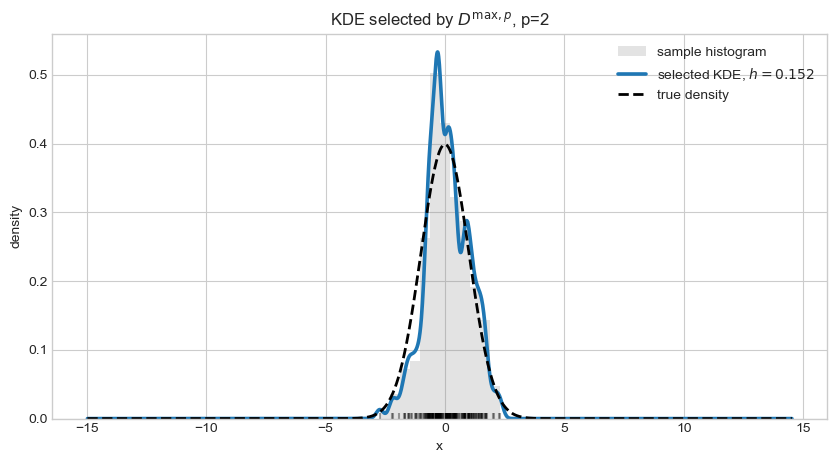

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(X, bins="auto", density=True, alpha=0.22, color="gray", label="sample histogram")
ax.plot(x_grid, kde_family[selected_index_max_p], lw=2.6, color="tab:blue", label=fr"selected KDE, $h={selected_h_max_p:.3g}$")
ax.plot(x_grid, truth, "--", lw=2, color="black", label="true density")
ax.scatter(X, np.zeros_like(X), marker="|", s=65, color="black", alpha=0.35)
ax.set_title(fr"KDE selected by $D^{{\max,p}}$, p={p_join:g}")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()


## 11. $D^{\max}_1$: exact one-dimensional overlap

For $p=1$, the same idempotent construction becomes especially interpretable. Since every KDE is a probability density,

$$
F_1(\widehat f_h)=\int \widehat f_h(x)\,dx=1.
$$

Therefore

$$
D^{\max}_{1,ij}
=F_1(\widehat f_i)+F_1(\widehat f_j)-F_1(\widehat f_i\vee \widehat f_j)
=\int \min\{\widehat f_i(x),\widehat f_j(x)\}\,dx.
$$

Equivalently,

$$
D^{\max}_{1,ij}
=1-\frac{1}{2}\int |\widehat f_i(x)-\widehat f_j(x)|\,dx.
$$

So this is exactly the overlap coefficient of the two KDE densities.

In one dimension this can be computed without numerical quadrature once the crossing points are known. Let

$$
-\infty=r_0<r_1<\cdots<r_K<r_{K+1}=\infty
$$

be the points where

$$
\widehat f_i(r_k)=\widehat f_j(r_k).
$$

On each interval $(r_k,r_{k+1})$, one KDE lies below the other. Hence

$$
D^{\max}_{1,ij}
=\sum_{k=0}^{K}
\int_{r_k}^{r_{k+1}}
\min\{\widehat f_i(x),\widehat f_j(x)\}\,dx.
$$

Each interval integral is just a KDE CDF difference. For the Gaussian kernel,

$$
\widehat F_h(x)=\frac{1}{n}\sum_{r=1}^n
\Phi\left(\frac{x-X_r}{h}\right),
$$

and for the Epanechnikov kernel,

$$
\widehat F_h(x)=\frac{1}{n}\sum_{r=1}^n A\left(\frac{x-X_r}{h}\right),
$$

where

$$
A(u)=
\begin{cases}
0, & u\le -1,\\
\frac12+\frac34u-\frac14u^3, & -1<u<1,\\
1, & u\ge 1.
\end{cases}
$$

The only non-closed part is finding the crossing points $r_k$. For KDE mixtures these usually do not have a symbolic formula, so the code below locates them by bracketing and bisection. After that, the actual masses are computed from the closed-form CDFs above.


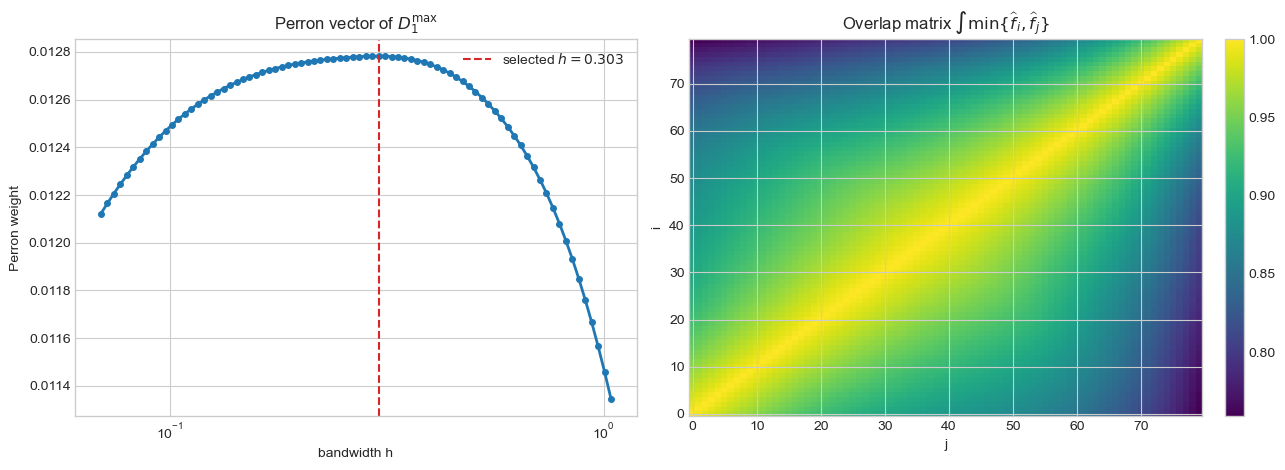

D_max_1 selected h = 0.302674


In [16]:
D_max_1 = trapz_integral(np.minimum(kde_family[:, None, :], kde_family[None, :, :]), axis=2)
D_max_1 = np.maximum((D_max_1 + D_max_1.T) / 2, 0.0)
np.fill_diagonal(D_max_1, 1.0)
perron_max_1 = principal_eigenvector_nonnegative(D_max_1)
selected_index_max_1 = int(np.argmax(perron_max_1))
selected_h_max_1 = float(h_grid[selected_index_max_1])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(h_grid, perron_max_1, marker="o", ms=4, lw=2)
axes[0].axvline(selected_h_max_1, color="tab:red", ls="--", label=fr"selected $h={selected_h_max_1:.3g}$")
axes[0].set_xscale("log")
axes[0].set_title(r"Perron vector of $D^{\max}_1$")
axes[0].set_xlabel("bandwidth h")
axes[0].set_ylabel("Perron weight")
axes[0].legend()

image = axes[1].imshow(D_max_1, origin="lower", aspect="auto", cmap="viridis")
axes[1].set_title(r"Overlap matrix $\int \min\{\widehat f_i,\widehat f_j\}$")
axes[1].set_xlabel("j")
axes[1].set_ylabel("i")
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f"D_max_1 selected h = {selected_h_max_1:.6g}")


## 12. Compare the $L^2$-based spectral selections

This plot compares the Perron vectors from $D^{(+)}_2$, $D^{(-)}_2$, and the idempotent max-overlap matrix. If `p_join = 2`, the max-overlap curve is exactly the $D^{\max}_2$ experiment; otherwise it shows $D^{\max,p}$ for the chosen exponent.


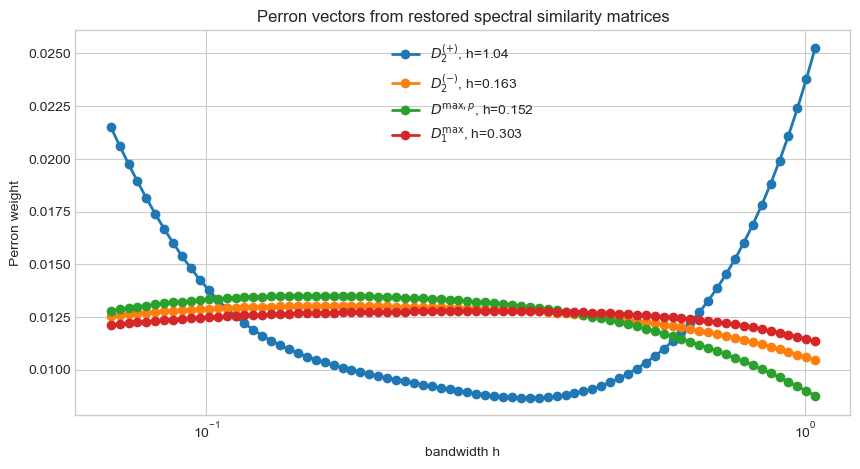

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(h_grid, perron_vector, marker="o", lw=2, label=fr"$D^{{(+)}}_2$, h={selected_h:.3g}")
ax.plot(h_grid, perron_minus, marker="o", lw=2, label=fr"$D^{{(-)}}_2$, h={selected_h_minus:.3g}")
ax.plot(h_grid, perron_max_p, marker="o", lw=2, label=fr"$D^{{\max,p}}$, h={selected_h_max_p:.3g}")
ax.plot(h_grid, perron_max_1, marker="o", lw=2, label=fr"$D^{{\max}}_1$, h={selected_h_max_1:.3g}")
ax.set_xscale("log")
ax.set_title("Perron vectors from restored spectral similarity matrices")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("Perron weight")
ax.legend()
plt.show()


## 13. Jensen-Shannon similarities: quadrature, oracle sampling, and fixed $N(0,1)$ sampling

The entropy method is based on the Shannon differential entropy

$$
H(f)=-\int f(x)\log f(x)\,dx.
$$

For KDEs,

$$
H(\widehat{f}_h)=-\int \widehat{f}_h(x)\log\left(\widehat{f}_h(x)\right)\,dx.
$$

This section estimates the entropy integrals by Monte Carlo importance sampling. For a proposal density $q$, draw

$$
Y_1,\dots,Y_M\sim q.
$$

Then, for any density $g$,

$$
\int g(x)\log g(x)\,dx
=
\mathbb E_q\left[\frac{g(Y)}{q(Y)}\log g(Y)\right].
$$

Therefore

$$
H(g)
\approx
-\frac{1}{M}\sum_{m=1}^M
\frac{g(Y_m)}{q(Y_m)}
\log(g(Y_m)).
$$

We compute two proposal choices:

1. the true simulation proposal

$$
q_{true}(x)=N(0,\sigma^2),
$$

which is useful as a simulation diagnostic but uses oracle information;

2. the fixed standard-normal proposal

$$
q_{std}(x)=N(0,1),
$$

which ignores the true value of $\sigma^2$ and therefore tests sensitivity to proposal mismatch.

Given two KDEs, define

$$
m_{ij}=\frac{\widehat{f}_i+\widehat{f}_j}{2}.
$$

The Jensen-Shannon divergence is

$$
JS(\widehat{f}_i,\widehat{f}_j)
=H(m_{ij})-\frac{1}{2}H(\widehat{f}_i)-\frac{1}{2}H(\widehat{f}_j).
$$

The similarity matrix is

$$
S^{JS}_{ij}=1-\frac{JS(\widehat{f}_i,\widehat{f}_j)}{\log 2}.
$$

Thus identical densities have similarity $1$, and more different densities have smaller similarity. Because Monte Carlo estimates have noise, the code clips tiny numerical violations back to the interval $[0,1]$.


In addition to the two Monte Carlo proposals, this section also computes an honest deterministic quadrature version using the trapezoidal rule on an $x$-grid.


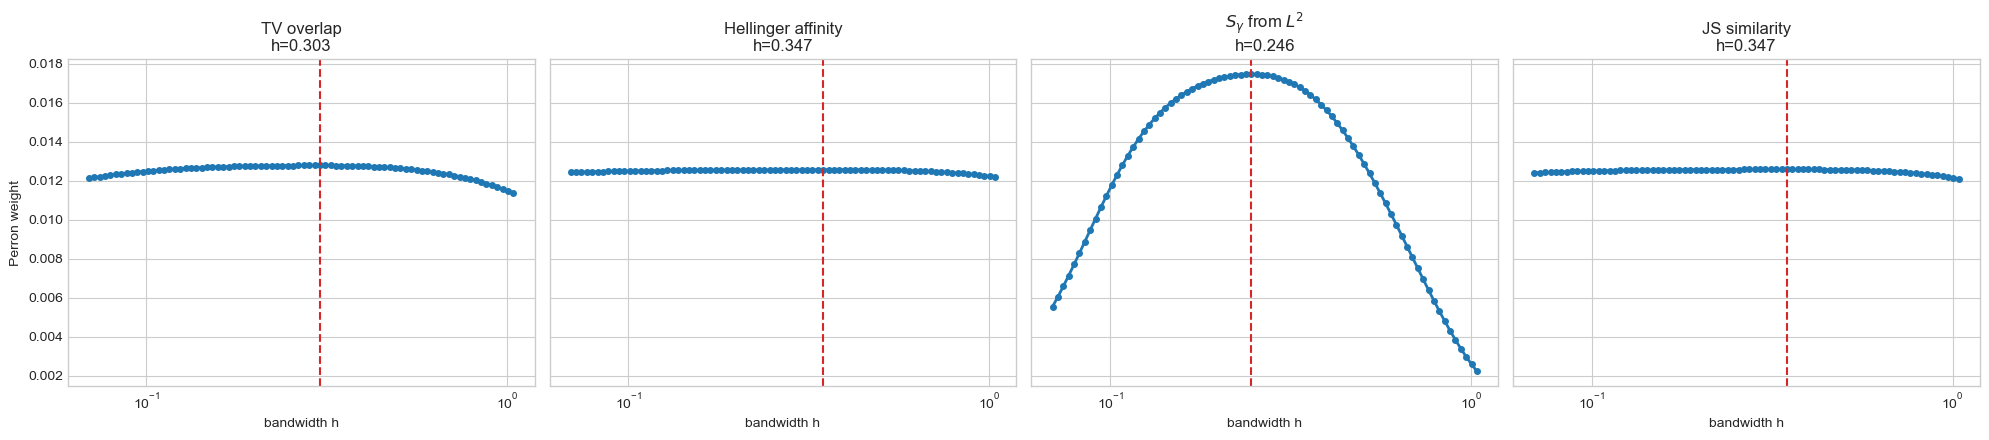

JS selected h = 0.347155
Hellinger selected h = 0.347155


In [18]:
# Deterministic quadrature Jensen-Shannon, Hellinger and TV similarities.
eps = 1e-300
kde_family_normalized = kde_family / trapz_integral(kde_family, axis=1)[:, None]

entropy_values = -trapz_integral(kde_family_normalized * np.log(np.maximum(kde_family_normalized, eps)), axis=1)
mixture_values = 0.5 * (kde_family_normalized[:, None, :] + kde_family_normalized[None, :, :])
mixture_entropy = -trapz_integral(mixture_values * np.log(np.maximum(mixture_values, eps)), axis=2)
JS_divergence = np.maximum(mixture_entropy - 0.5 * entropy_values[:, None] - 0.5 * entropy_values[None, :], 0.0)
JS_similarity = 1.0 - JS_divergence / np.log(2.0)
JS_similarity = np.clip((JS_similarity + JS_similarity.T) / 2, 0.0, 1.0)
np.fill_diagonal(JS_similarity, 1.0)

Hellinger_affinity = trapz_integral(np.sqrt(kde_family_normalized[:, None, :] * kde_family_normalized[None, :, :]), axis=2)
Hellinger_affinity = np.clip((Hellinger_affinity + Hellinger_affinity.T) / 2, 0.0, 1.0)
np.fill_diagonal(Hellinger_affinity, 1.0)

TV_overlap = trapz_integral(np.minimum(kde_family_normalized[:, None, :], kde_family_normalized[None, :, :]), axis=2)
TV_overlap = np.clip((TV_overlap + TV_overlap.T) / 2, 0.0, 1.0)
np.fill_diagonal(TV_overlap, 1.0)

positive_distances = l2_distance[l2_distance > 0]
gamma_l2 = 1.0 / np.median(positive_distances**2) if len(positive_distances) else 1.0
S_gamma_l2 = np.exp(-gamma_l2 * l2_distance**2)
np.fill_diagonal(S_gamma_l2, 1.0)

perron_js = principal_eigenvector_nonnegative(JS_similarity)
perron_hellinger = principal_eigenvector_nonnegative(Hellinger_affinity)
perron_tv = principal_eigenvector_nonnegative(TV_overlap)
perron_sgamma = principal_eigenvector_nonnegative(S_gamma_l2)

selected_index_js = int(np.argmax(perron_js)); selected_h_js = float(h_grid[selected_index_js])
selected_index_hellinger = int(np.argmax(perron_hellinger)); selected_h_hellinger = float(h_grid[selected_index_hellinger])
selected_index_tv = int(np.argmax(perron_tv)); selected_h_tv = float(h_grid[selected_index_tv])
selected_index_sgamma = int(np.argmax(perron_sgamma)); selected_h_sgamma = float(h_grid[selected_index_sgamma])

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, name, vec, h_sel in [
    (axes[0], "TV overlap", perron_tv, selected_h_tv),
    (axes[1], "Hellinger affinity", perron_hellinger, selected_h_hellinger),
    (axes[2], r"$S_\gamma$ from $L^2$", perron_sgamma, selected_h_sgamma),
    (axes[3], "JS similarity", perron_js, selected_h_js),
]:
    ax.plot(h_grid, vec, marker="o", ms=4, lw=2)
    ax.axvline(h_sel, color="tab:red", ls="--")
    ax.set_xscale("log")
    ax.set_title(f"{name}\nh={h_sel:.3g}")
    ax.set_xlabel("bandwidth h")
axes[0].set_ylabel("Perron weight")
plt.tight_layout()
plt.show()

print(f"JS selected h = {selected_h_js:.6g}")
print(f"Hellinger selected h = {selected_h_hellinger:.6g}")


## 14. Compare all selected bandwidths

This plot compares all spectral selectors with the oracle benchmark.


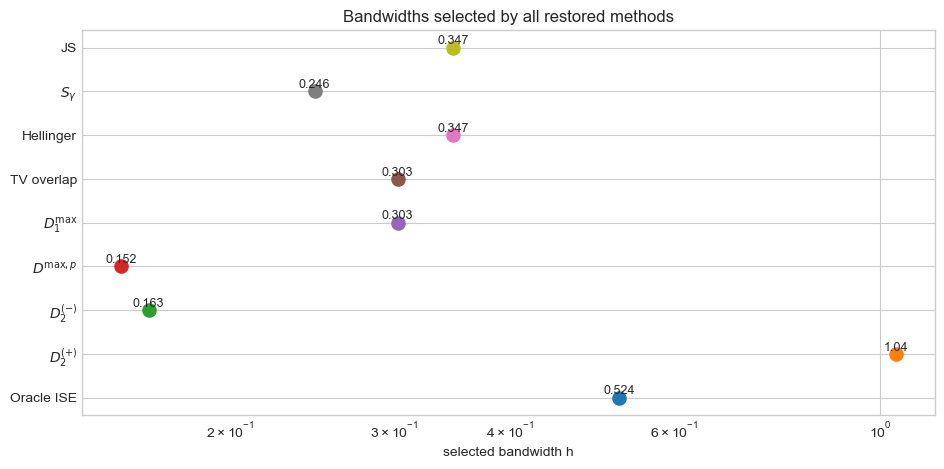

Oracle ISE         index= 59, h=0.523806, ISE=0.001781
$D^{(+)}_2$        index= 79, h=1.03972, ISE=0.0186471
$D^{(-)}_2$        index= 25, h=0.163307, ISE=0.014464
$D^{\max,p}$       index= 23, h=0.152486, ISE=0.0154878
$D^{\max}_1$       index= 43, h=0.302674, ISE=0.00614153
TV overlap         index= 43, h=0.302674, ISE=0.00614153
Hellinger          index= 47, h=0.347155, ISE=0.00448929
$S_\gamma$         index= 37, h=0.246406, ISE=0.00882799
JS                 index= 47, h=0.347155, ISE=0.00448929


In [19]:
selection_summary = [
    ("Oracle ISE", oracle_h, oracle_index),
    (r"$D^{(+)}_2$", selected_h, selected_index),
    (r"$D^{(-)}_2$", selected_h_minus, selected_index_minus),
    (r"$D^{\max,p}$", selected_h_max_p, selected_index_max_p),
    (r"$D^{\max}_1$", selected_h_max_1, selected_index_max_1),
    ("TV overlap", selected_h_tv, selected_index_tv),
    ("Hellinger", selected_h_hellinger, selected_index_hellinger),
    (r"$S_\gamma$", selected_h_sgamma, selected_index_sgamma),
    ("JS", selected_h_js, selected_index_js),
]

fig, ax = plt.subplots(figsize=(11, 5))
for k, (name, h_sel, _) in enumerate(selection_summary):
    ax.scatter(h_sel, k, s=90)
    ax.text(h_sel, k + 0.08, f"{h_sel:.3g}", ha="center", fontsize=9)
ax.set_xscale("log")
ax.set_yticks(range(len(selection_summary)))
ax.set_yticklabels([name for name, _, _ in selection_summary])
ax.set_xlabel("selected bandwidth h")
ax.set_title("Bandwidths selected by all restored methods")
plt.show()

for name, h_sel, idx in selection_summary:
    print(f"{name:18s} index={idx:3d}, h={h_sel:.6g}, ISE={ise_values[idx]:.6g}")


## 15. Inspect the KDE selected by the entropy/JS matrix

This plot shows the KDE selected by the entropy/Jensen-Shannon matrix together with the true Gaussian density. The histogram, oracle KDE, and rug marks are intentionally omitted so the comparison stays visually focused: selected KDE versus known ground truth.


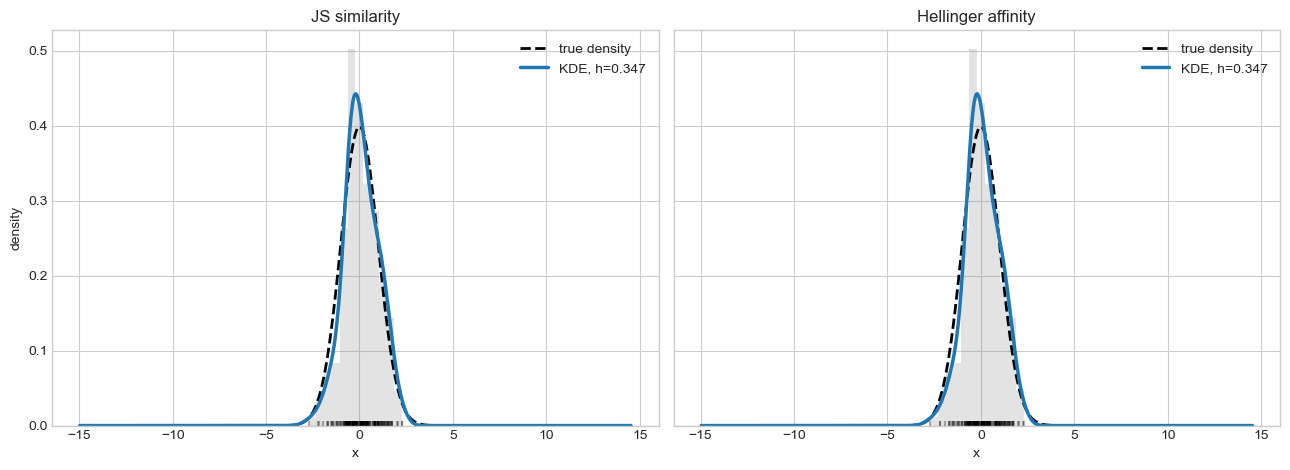

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, name, idx in [
    (axes[0], "JS similarity", selected_index_js),
    (axes[1], "Hellinger affinity", selected_index_hellinger),
]:
    ax.hist(X, bins="auto", density=True, alpha=0.22, color="gray")
    ax.plot(x_grid, truth, "--", lw=2, color="black", label="true density")
    ax.plot(x_grid, kde_family[idx], lw=2.5, label=fr"KDE, h={h_grid[idx]:.3g}")
    ax.scatter(X, np.zeros_like(X), marker="|", s=55, color="black", alpha=0.30)
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()


## 16. Fixed-$n$ simulation: empirical bandwidth distributions for oracle and JS quadrature

In this experiment the sample size is fixed. We repeat the following procedure $R=100$ times:

1. draw a new sample

$$
X_1,\dots,X_n\sim N(0,\sigma^2),
$$

2. compute the oracle bandwidth

$$
h_{oracle}=\arg\min_h \int (\widehat f_h(x)-f(x))^2\,dx,
$$

3. compute the honest Jensen-Shannon bandwidth using deterministic quadrature,

$$
h_{JS}^{grid}=h_{\arg\max_i v_i},
$$

where $v$ is the Perron vector of the JS similarity matrix computed by trapezoidal integration.

The plot shows the empirical relative frequencies with which each bandwidth grid value is selected by the two methods.


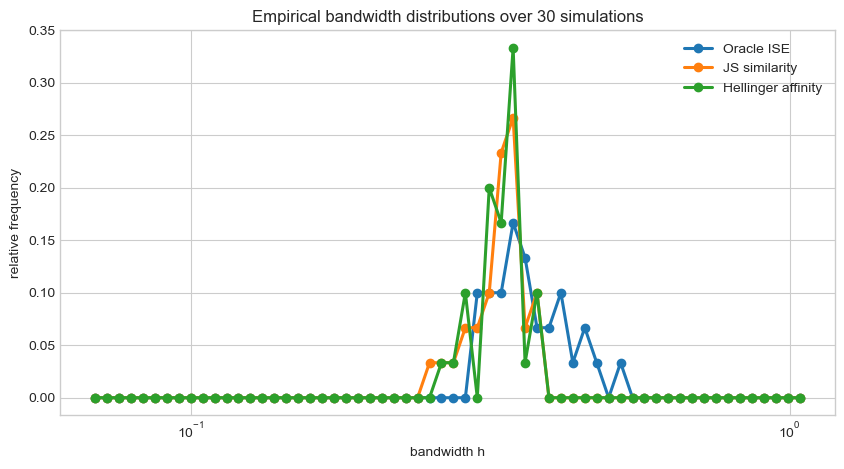

Oracle ISE          : modal h = 0.345546, median h = 0.361775
JS similarity       : modal h = 0.345546, median h = 0.330044
Hellinger affinity  : modal h = 0.345546, median h = 0.330044


In [21]:
# Restored fixed-n empirical distribution experiment for oracle, JS, and Hellinger.
num_simulations_distribution = 30
n_distribution = 200
sigma2_distribution = 1.0
n_h_distribution = 60
base_seed_distribution = 91_000

h_center_distribution = np.sqrt(sigma2_distribution) * n_distribution ** (-1 / 5)
h_grid_distribution = np.geomspace(0.20 * h_center_distribution, 3.00 * h_center_distribution, n_h_distribution)


def select_js_and_hellinger_for_sample(samples, h_grid, sigma2=1.0):
    margin = 6.0 * (np.sqrt(sigma2) + np.max(h_grid))
    x_grid_local = np.linspace(samples.min() - margin, samples.max() + margin, 1_501)
    kde_values = np.array([kde_eval(x_grid_local, samples, h=h, kernel="gaussian") for h in h_grid])
    masses = trapz_integral(kde_values, x=x_grid_local, axis=1)
    kde_values = kde_values / masses[:, None]
    truth_local = normal_pdf(x_grid_local, sigma2=sigma2)
    ise = trapz_integral((kde_values - truth_local[None, :]) ** 2, x=x_grid_local, axis=1)

    eps = 1e-300
    entropy = -trapz_integral(kde_values * np.log(np.maximum(kde_values, eps)), x=x_grid_local, axis=1)
    mixtures = 0.5 * (kde_values[:, None, :] + kde_values[None, :, :])
    mixture_entropy = -trapz_integral(mixtures * np.log(np.maximum(mixtures, eps)), x=x_grid_local, axis=2)
    js = np.maximum(mixture_entropy - 0.5 * entropy[:, None] - 0.5 * entropy[None, :], 0.0)
    js_similarity = np.clip(1.0 - js / np.log(2.0), 0.0, 1.0)
    np.fill_diagonal(js_similarity, 1.0)

    hellinger = trapz_integral(np.sqrt(kde_values[:, None, :] * kde_values[None, :, :]), x=x_grid_local, axis=2)
    hellinger = np.clip((hellinger + hellinger.T) / 2, 0.0, 1.0)
    np.fill_diagonal(hellinger, 1.0)

    oracle_idx = int(np.argmin(ise))
    js_idx = int(np.argmax(principal_eigenvector_nonnegative(js_similarity)))
    hell_idx = int(np.argmax(principal_eigenvector_nonnegative(hellinger)))
    return oracle_idx, js_idx, hell_idx, ise

results_distribution = []
for simulation in range(num_simulations_distribution):
    rng = np.random.default_rng(base_seed_distribution + simulation)
    samples = rng.normal(0.0, np.sqrt(sigma2_distribution), size=n_distribution)
    oracle_idx, js_idx, hell_idx, ise = select_js_and_hellinger_for_sample(samples, h_grid_distribution, sigma2_distribution)
    results_distribution.append((oracle_idx, js_idx, hell_idx))

results_distribution = np.array(results_distribution, dtype=int)
labels_and_columns = [("Oracle ISE", 0), ("JS similarity", 1), ("Hellinger affinity", 2)]

fig, ax = plt.subplots(figsize=(10, 5))
for label, col in labels_and_columns:
    frequencies = np.bincount(results_distribution[:, col], minlength=len(h_grid_distribution)) / num_simulations_distribution
    ax.plot(h_grid_distribution, frequencies, marker="o", lw=2.2, label=label)
ax.set_xscale("log")
ax.set_title(f"Empirical bandwidth distributions over {num_simulations_distribution} simulations")
ax.set_xlabel("bandwidth h")
ax.set_ylabel("relative frequency")
ax.legend()
plt.show()

for label, col in labels_and_columns:
    indices = results_distribution[:, col]
    modal_index = int(np.argmax(np.bincount(indices, minlength=len(h_grid_distribution))))
    print(f"{label:20s}: modal h = {h_grid_distribution[modal_index]:.6g}, median h = {np.median(h_grid_distribution[indices]):.6g}")


## 17. Consistency-style plot: sample size versus selected KDE error

This experiment checks the direct consistency quantity

$$
\left\|f-\widehat f_{\widehat h_n}\right\|_2.
$$

For each sample size $n$, we repeat the simulation several times. In each repetition we choose two bandwidths:

1. the oracle bandwidth from minimum integrated squared error;
2. the JS-quadrature bandwidth from the Perron vector of the grid-integrated JS matrix.

Because the true density is known in this simulation, we can compute the exact integrated squared error at both selected bandwidths. The plotted quantity is

$$
\left\|f-\widehat f_{\widehat h_n}\right\|_2
=
\sqrt{ISE(\widehat h_n)}.
$$

If the selected KDE is consistent, this error should decrease as $n$ grows.


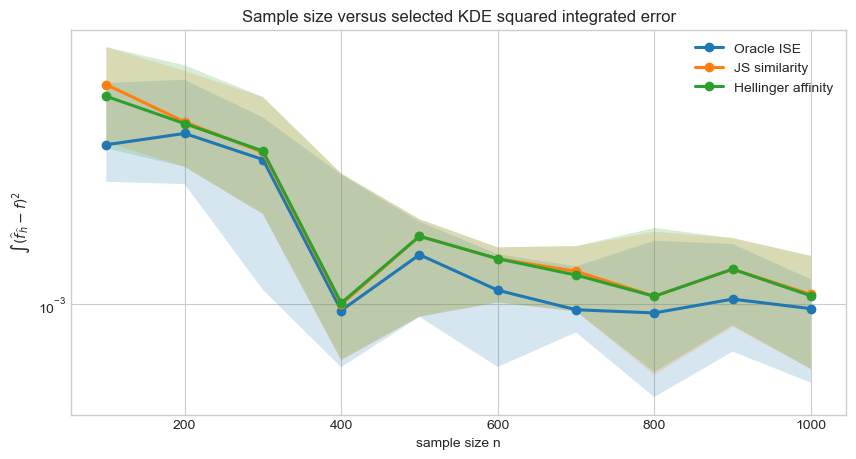

In [22]:
# Restored consistency-style experiment: n versus selected KDE squared integrated error.
n_values_consistency = np.arange(100, 1001, 100)
num_simulations_consistency = 10
n_h_consistency = 50
base_seed_consistency = 92_000
sigma2_consistency = 1.0

consistency_rows = []
for n_current in n_values_consistency:
    h_center_current = np.sqrt(sigma2_consistency) * int(n_current) ** (-1 / 5)
    h_grid_current = np.geomspace(0.20 * h_center_current, 3.00 * h_center_current, n_h_consistency)
    for simulation in range(num_simulations_consistency):
        rng = np.random.default_rng(base_seed_consistency + 10_000 * int(n_current) + simulation)
        samples = rng.normal(0.0, np.sqrt(sigma2_consistency), size=int(n_current))
        oracle_idx, js_idx, hell_idx, ise = select_js_and_hellinger_for_sample(samples, h_grid_current, sigma2_consistency)
        consistency_rows.extend([
            (int(n_current), "Oracle ISE", h_grid_current[oracle_idx], ise[oracle_idx]),
            (int(n_current), "JS similarity", h_grid_current[js_idx], ise[js_idx]),
            (int(n_current), "Hellinger affinity", h_grid_current[hell_idx], ise[hell_idx]),
        ])

fig, ax = plt.subplots(figsize=(10, 5))
for method in ["Oracle ISE", "JS similarity", "Hellinger affinity"]:
    medians = []
    q25 = []
    q75 = []
    for n_current in n_values_consistency:
        values = np.array([row[3] for row in consistency_rows if row[0] == int(n_current) and row[1] == method])
        medians.append(np.median(values))
        q25.append(np.quantile(values, 0.25))
        q75.append(np.quantile(values, 0.75))
    medians = np.array(medians); q25 = np.array(q25); q75 = np.array(q75)
    ax.plot(n_values_consistency, medians, marker="o", lw=2.2, label=method)
    ax.fill_between(n_values_consistency, q25, q75, alpha=0.18)
ax.set_yscale("log")
ax.set_title("Sample size versus selected KDE squared integrated error")
ax.set_xlabel("sample size n")
ax.set_ylabel(r"$\int (\widehat f_{\widehat h}-f)^2$")
ax.legend()
plt.show()


## 18. Multimodal experiment: JS bandwidth selection away from the Gaussian case

Up to now, the simulated data came from a single Gaussian density. That is a useful first test, but it is also a very friendly case: the true density has one mode, symmetric tails, and no separated structure.

Here we keep the Jensen-Shannon quadrature method as the main selector and test it on a more difficult multimodal density. The data are drawn from a Gaussian mixture

$$
f(x)=\sum_{k=1}^K w_k\,\varphi_{\mu_k,\sigma_k^2}(x),
$$

where $w_k>0$ and $\sum_k w_k=1$. In the default experiment below, $K=3$: there is a left mode, a wider middle component, and a right mode. This creates a density with multiple visible scales.

The JS selector itself does not use the true density. It only uses the KDE family

$$
\widehat f_{h_1},\dots,\widehat f_{h_N}
$$

and computes the quadrature approximation of

$$
S^{JS}_{ij}=1-\frac{JS(\widehat f_i,\widehat f_j)}{\log 2}.
$$

The selected bandwidth is the grid value where the principal eigenvector is maximal:

$$
\widehat h_{JS}=h_{\arg\max_i v_i}.
$$

Because this is still a simulation, we also compute an oracle bandwidth for comparison:

$$
h_{oracle}=\arg\min_h \int (\widehat f_h(x)-f(x))^2\,dx.
$$

For this section the oracle is only a benchmark. The JS choice is the method of interest.


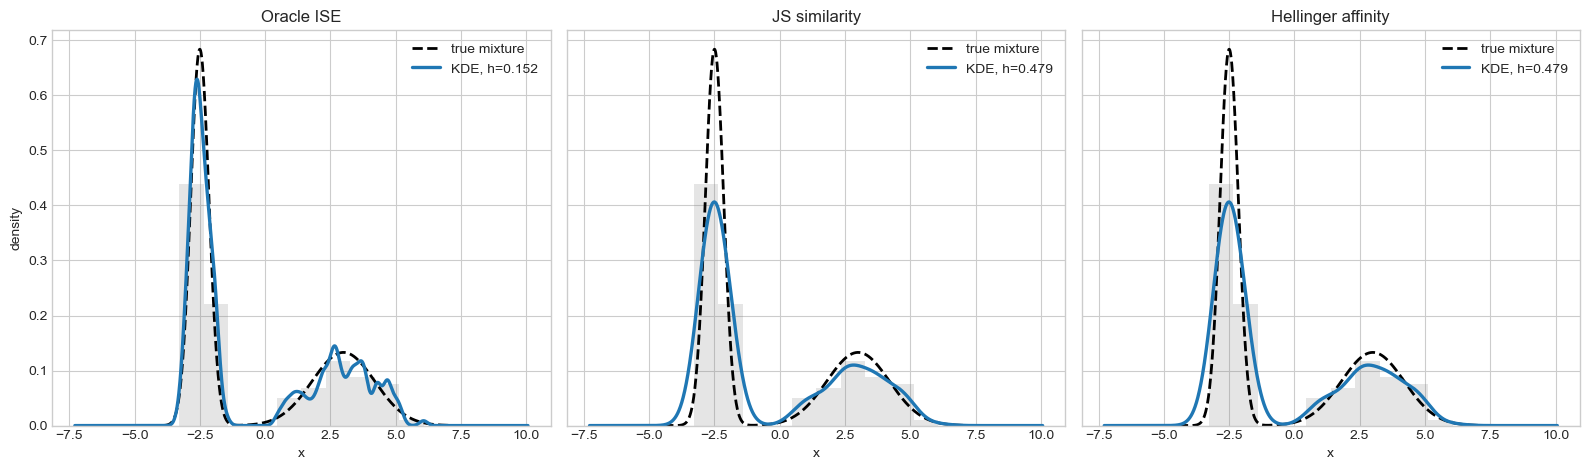

mixture oracle h = 0.151952
mixture JS h = 0.47862
mixture Hellinger h = 0.47862


In [23]:
# Restored multimodal experiment: JS/Hellinger spectral selection on a two-component Gaussian mixture.
mixture_weights = np.array([0.60, 0.40])
mixture_means = np.array([-2.5, 3.0])
mixture_sigmas = np.array([0.35, 1.20])
n_mixture = 300
seed_mixture = 1234
n_h_mixture = 70


def mixture_pdf(x, weights, means, sigmas):
    out = np.zeros_like(np.asarray(x, dtype=float))
    for w, m, s in zip(weights, means, sigmas):
        out += w * np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
    return out

rng = np.random.default_rng(seed_mixture)
components = rng.choice(len(mixture_weights), size=n_mixture, p=mixture_weights / mixture_weights.sum())
X_mix = rng.normal(mixture_means[components], mixture_sigmas[components])
mixture_variance = np.sum(mixture_weights * (mixture_sigmas**2 + mixture_means**2)) - np.sum(mixture_weights * mixture_means) ** 2
h_center_mix = np.sqrt(mixture_variance) * n_mixture ** (-1 / 5)
h_grid_mix = np.geomspace(0.08 * h_center_mix, 2.50 * h_center_mix, n_h_mixture)
x_grid_mix = np.linspace(X_mix.min() - 4.0, X_mix.max() + 4.0, 2_001)
kde_mix = np.array([kde_eval(x_grid_mix, X_mix, h=h, kernel="gaussian") for h in h_grid_mix])
kde_mix = kde_mix / trapz_integral(kde_mix, x=x_grid_mix, axis=1)[:, None]
truth_mix = mixture_pdf(x_grid_mix, mixture_weights, mixture_means, mixture_sigmas)
ise_mix = trapz_integral((kde_mix - truth_mix[None, :]) ** 2, x=x_grid_mix, axis=1)

# JS and Hellinger matrices for the mixture KDE family.
eps = 1e-300
entropy_mix = -trapz_integral(kde_mix * np.log(np.maximum(kde_mix, eps)), x=x_grid_mix, axis=1)
mixtures_mix = 0.5 * (kde_mix[:, None, :] + kde_mix[None, :, :])
mixture_entropy_mix = -trapz_integral(mixtures_mix * np.log(np.maximum(mixtures_mix, eps)), x=x_grid_mix, axis=2)
js_mix = np.maximum(mixture_entropy_mix - 0.5 * entropy_mix[:, None] - 0.5 * entropy_mix[None, :], 0.0)
S_js_mix = np.clip(1.0 - js_mix / np.log(2.0), 0.0, 1.0)
np.fill_diagonal(S_js_mix, 1.0)
S_hell_mix = trapz_integral(np.sqrt(kde_mix[:, None, :] * kde_mix[None, :, :]), x=x_grid_mix, axis=2)
S_hell_mix = np.clip((S_hell_mix + S_hell_mix.T) / 2, 0.0, 1.0)
np.fill_diagonal(S_hell_mix, 1.0)

oracle_mix_idx = int(np.argmin(ise_mix))
js_mix_idx = int(np.argmax(principal_eigenvector_nonnegative(S_js_mix)))
hell_mix_idx = int(np.argmax(principal_eigenvector_nonnegative(S_hell_mix)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, name, idx in [
    (axes[0], "Oracle ISE", oracle_mix_idx),
    (axes[1], "JS similarity", js_mix_idx),
    (axes[2], "Hellinger affinity", hell_mix_idx),
]:
    ax.hist(X_mix, bins="auto", density=True, alpha=0.20, color="gray")
    ax.plot(x_grid_mix, truth_mix, "k--", lw=2, label="true mixture")
    ax.plot(x_grid_mix, kde_mix[idx], lw=2.4, label=fr"KDE, h={h_grid_mix[idx]:.3g}")
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

print(f"mixture oracle h = {h_grid_mix[oracle_mix_idx]:.6g}")
print(f"mixture JS h = {h_grid_mix[js_mix_idx]:.6g}")
print(f"mixture Hellinger h = {h_grid_mix[hell_mix_idx]:.6g}")


## 19. Five-peak experiment: JS bandwidth selection on a harder multimodal density

This block repeats the idea from Block 18, but now the target density has five separated peaks. The purpose is to make the scale-selection problem more demanding: the KDE has to balance local peak resolution against global smoothing.

We sample from the Gaussian mixture

$$
f(x)=\sum_{k=1}^5 w_k\,\varphi_{\mu_k,\sigma_k^2}(x).
$$

The JS selector is again the main method. It uses only the KDE family and the quadrature approximation of the Jensen-Shannon matrix

$$
S^{JS}_{ij}=1-\frac{JS(\widehat f_i,\widehat f_j)}{\log 2}.
$$

The chosen bandwidth is

$$
\widehat h_{JS}=h_{\arg\max_i v_i},
$$

where $v$ is the principal eigenvector of $S^{JS}$. Since this is simulated data, we also compute the oracle bandwidth

$$
h_{oracle}=\arg\min_h \int (\widehat f_h(x)-f(x))^2\,dx
$$

as a benchmark. The oracle uses the known five-peak density; the JS choice does not.


## 20. Heavy-tailed experiment: JS bandwidth selection for Student-$t$ samples

Blocks 18 and 19 tested multimodal data. This block tests a different kind of difficulty: heavy tails. The sample is drawn from a scaled Student-$t$ distribution

$$
X_i \sim s\,t_\nu.
$$

For small degrees of freedom $\nu$, the density has much heavier tails than a Gaussian. This means that a sample may contain outliers far away from the main mass of the distribution. A bandwidth selector can then face a tension:

- small bandwidths can create isolated bumps around tail observations;
- large bandwidths can hide the central shape;
- an intermediate bandwidth should smooth tail observations without destroying the main peak.

The JS selector is again the main method. It uses only the KDE family and computes

$$
S^{JS}_{ij}=1-\frac{JS(\widehat f_i,\widehat f_j)}{\log 2}
$$

by quadrature. The chosen bandwidth is

$$
\widehat h_{JS}=h_{\arg\max_i v_i},
$$

where $v$ is the principal eigenvector of the JS matrix.

Since this is simulated data, we also compute an oracle benchmark

$$
h_{oracle}=\arg\min_h \int (\widehat f_h(x)-f(x))^2\,dx.
$$

Unlike the Gaussian and Gaussian-mixture cases, the oracle integral is computed by numerical quadrature here. The JS selector itself still does not use the true density.


## 21. Heavy-tailed repeated experiment: empirical distribution of selected bandwidths

This block repeats the heavy-tailed Student-$t$ experiment many times and compares the empirical distributions of the two selected bandwidths:

1. the JS-quadrature bandwidth

$$
\widehat h_{JS}=h_{\arg\max_i v_i},
$$

where $v$ is the principal eigenvector of the JS similarity matrix;

2. the oracle bandwidth

$$
h_{oracle}=\arg\min_h \int (\widehat f_h(x)-f(x))^2\,dx.
$$

The plot is analogous to Block 16, but now the data are heavy-tailed:

$$
X_i\sim s\,t_\nu.
$$

This shows whether the two selection rules concentrate around similar bandwidth regions across repeated samples, or whether heavy-tail outliers make one of the choices much more variable.


## 22. Multiple oracle minima: competing small-scale and large-scale bandwidths

This block replaces the previous broad-plateau experiment with a more explicit scale-conflict example. The data are sampled from a two-scale Gaussian mixture:

$$
f(x)=0.85\,\varphi_{0,1^2}(x)+0.15\,\varphi_{2.5,0.08^2}(x).
$$

The first component is a broad background density. The second component is a narrow spike. A single global bandwidth has to decide between two incompatible goals:

- small bandwidth: resolve the narrow spike;
- large bandwidth: smooth the broad background component well.

Because of this, the oracle curve

$$
h\mapsto ISE(h)=\int (\widehat f_h(x)-f(x))^2\,dx
$$

can have more than one local minimum. Each local minimum corresponds to a different scale decision.

The block detects local minima of the ISE curve and compares three choices:

1. the global oracle minimum;
2. the global JS Perron choice;
3. the Perron choice restricted to the local ISE minima.

The third choice is the most direct “Perron reweighting” interpretation here:

$$
\widehat i_{local-PF}
=
\arg\max_{i\in L} v_i,
$$

where $L$ is the set of local minima of the ISE curve and $v$ is the JS Perron vector.


## 23. Student-$t_3$ comparison: oracle, JS spectral, and Sheather--Jones plug-in

This experiment compares three bandwidth choices on a heavy-tailed sample

$$
X_1,
\dots,
X_n
\overset{iid}{\sim}
t_3,
\qquad n=100.
$$

The three bandwidths are:

1. **oracle bandwidth**, computed by minimizing the numerical integrated squared error against the known $t_3$ density;
2. **JS spectral bandwidth**, computed from the Perron vector of the Jensen--Shannon similarity matrix;
3. **Sheather--Jones plug-in bandwidth**, implemented here as a self-contained Gaussian-kernel plug-in selector using the AMISE formula and a pilot estimate of $R(f'')=\int (f''(x))^2\,dx$.

The Sheather--Jones selector is included as a classical plug-in benchmark. The implementation below is intentionally written in pure Python so the notebook does not depend on R's `bw.SJ`.


## 24. Repeated Student-$t_{1.5}$ comparison: bandwidth distributions for several sample sizes

This block repeats the bandwidth-comparison experiment for a heavier-tailed Student distribution,

$$
X_i \overset{iid}{\sim} t_{1.5}.
$$

The experiment is run for five sample sizes:

$$
n\in\{100,500,1000,2000,5000\}.
$$

For each sample size, we draw `num_simulations_student_distribution = 100` independent samples and compute three bandwidths:

1. the oracle bandwidth from minimum numerical ISE;
2. the JS spectral bandwidth from the Perron vector;
3. the Sheather--Jones plug-in bandwidth.

The plot shows one panel per sample size. In each panel, all three bandwidth choices are shown as relative-frequency curves over the same bandwidth grid. The Sheather--Jones bandwidth is continuous, so it is assigned to the nearest grid point in log-bandwidth distance for plotting.

For speed, this block uses a grid/FFT approximation of the Gaussian KDEs. This avoids the expensive pairwise Gram-matrix computation, which would be too slow for 100 repetitions at $n=1000$.


## 25. Diagnostic experiment: when do distance matrices select boundary scales?

This block is not a bandwidth-selection method. It is a diagnostic experiment for the question:

> If we put distances between KDEs directly into the Perron-vector pipeline, is the boundary behavior caused by the distance orientation itself, by the monotone norm profile, by the bandwidth grid, or by the particular geometry of the KDE path?

For one simulated sample and a bandwidth grid

$$
0<h_1<\cdots<h_N,
$$

we compute KDEs

$$
\widehat f_i=\widehat f_{h_i}.
$$

For several distances $d$, we form the distance matrix

$$
D^{(d)}_{ij}=d(\widehat f_i,\widehat f_j),
$$

and compute its Perron vector

$$
D^{(d)}v^{(d)}=\lambda_d v^{(d)},
\qquad
v^{(d)}\geq 0,
\qquad
\sum_i v_i^{(d)}=1.
$$

The important interpretation is

$$
\lambda_d v_i^{(d)}
=
\sum_j d(\widehat f_i,\widehat f_j)v_j^{(d)}.
$$

Thus a raw distance matrix ranks KDEs by weighted farness, not by stability.

We compare the following distances, approximated on a numerical grid:

$$
d_{L^1}(f,g)=\int |f-g|,
$$

$$
d_{L^2}(f,g)=\left(\int (f-g)^2\right)^{1/2},
$$

$$
d_{L^\infty}(f,g)=\sup_x |f(x)-g(x)|,
$$

$$
d_H(f,g)=\left(\int (\sqrt f-\sqrt g)^2\right)^{1/2},
$$

and

$$
d_{JS}(f,g)=\sqrt{JS(f,g)}.
$$

Total variation is not plotted separately because

$$
d_{TV}(f,g)=\frac12 d_{L^1}(f,g),
$$

so it has the same Perron vector as $d_{L^1}$.

As a norm-profile control for $p=2$, we also compute

$$
R_{ij}=\left|\|\widehat f_i\|_2-\|\widehat f_j\|_2\right|.
$$

If $D^{(L^2)}$ behaves similarly to $R$, then the monotone decay of $h\mapsto \|\widehat f_h\|_2$ is a plausible explanation for the boundary behavior.

Finally, we compare raw $L^2$ distances with shape-normalized $L^2$ distances. Define

$$
g_i=\frac{\widehat f_i}{\|\widehat f_i\|_2}.
$$

Then

$$
D^{\mathrm{shape}}_{ij}=\|g_i-g_j\|_2.
$$

If the endpoint peak disappears after this normalization, then the raw norm profile was carrying much of the effect.

The diagnostic uses a geometric bandwidth grid, so equal index steps correspond to constant multiplicative changes in bandwidth. This matches the scale geometry studied throughout the notebook.


## 26. Robinson dissimilarity test for the KDE distance matrices

A distance matrix ordered by bandwidth is a Robinson dissimilarity if distances do not decrease when moving away from the diagonal. Equivalently, for the bandwidth order

$$
h_1<\cdots<h_N,
$$

we want

$$
i<j<k
\quad\Longrightarrow\quad
D_{ik}\geq \max\{D_{ij},D_{jk}\}.
$$

For KDE distance matrices this asks whether larger scale separation produces larger KDE dissimilarity in the bandwidth order.

This block tests the Robinson property for each distance from Section 25. It reports two diagnostics:

1. **Triple violation rate:** the fraction of inequalities

$$
D_{ik}\geq D_{ij},
\qquad
D_{ik}\geq D_{jk}
$$

that fail over triples $i<j<k$.

2. **Adjacent violation rate:** the fraction of local monotonicity inequalities that fail when moving away from the diagonal along rows.

A value close to zero means the matrix is close to Robinson in the bandwidth order. If the value is exactly zero, the tested matrix is Robinson up to numerical tolerance.

## 27. Raw functional and norm profiles along the bandwidth path

The previous distance diagnostics compare pairs of KDEs. This block plots the one-point functionals associated with the same distance families.

For each bandwidth $h_i$, we compute

$$
\|\widehat f_{h_i}\|_1,
\qquad
\|\widehat f_{h_i}\|_2,
\qquad
\|\widehat f_{h_i}\|_\infty.
$$

For the Hellinger geometry we also plot

$$
\|\sqrt{\widehat f_{h_i}}\|_2,
$$

which should equal $1$ for exactly normalized densities. For the Jensen--Shannon construction we plot the Shannon entropy

$$
H(\widehat f_{h_i})=-\int \widehat f_{h_i}(x)\log \widehat f_{h_i}(x)\,dx.
$$

These profiles help separate effects caused by raw norm monotonicity from effects caused by the full pairwise distance geometry.

## 28. Rate-controlled Hellinger selector: forcing the correct KDE scaling

The spectral selector only chooses from the bandwidth grid that we give it. Therefore, to make the asymptotic scaling explicit, we use a grid of the form

$$
h_i^{(n)}=c_i\, n^{-1/5},
\qquad
0<c_1<\cdots<c_N.
$$

The constants $c_i$ are fixed across sample sizes. Hence every bandwidth selected from this grid satisfies

$$
\widehat h_n\to0,
\qquad
n\widehat h_n\to\infty,
$$

as long as the selected constants stay inside the fixed finite interval $[c_1,c_N]$. This block tests the Hellinger spectral selector again under this simple rate-controlled grid with no unknown scale parameter.


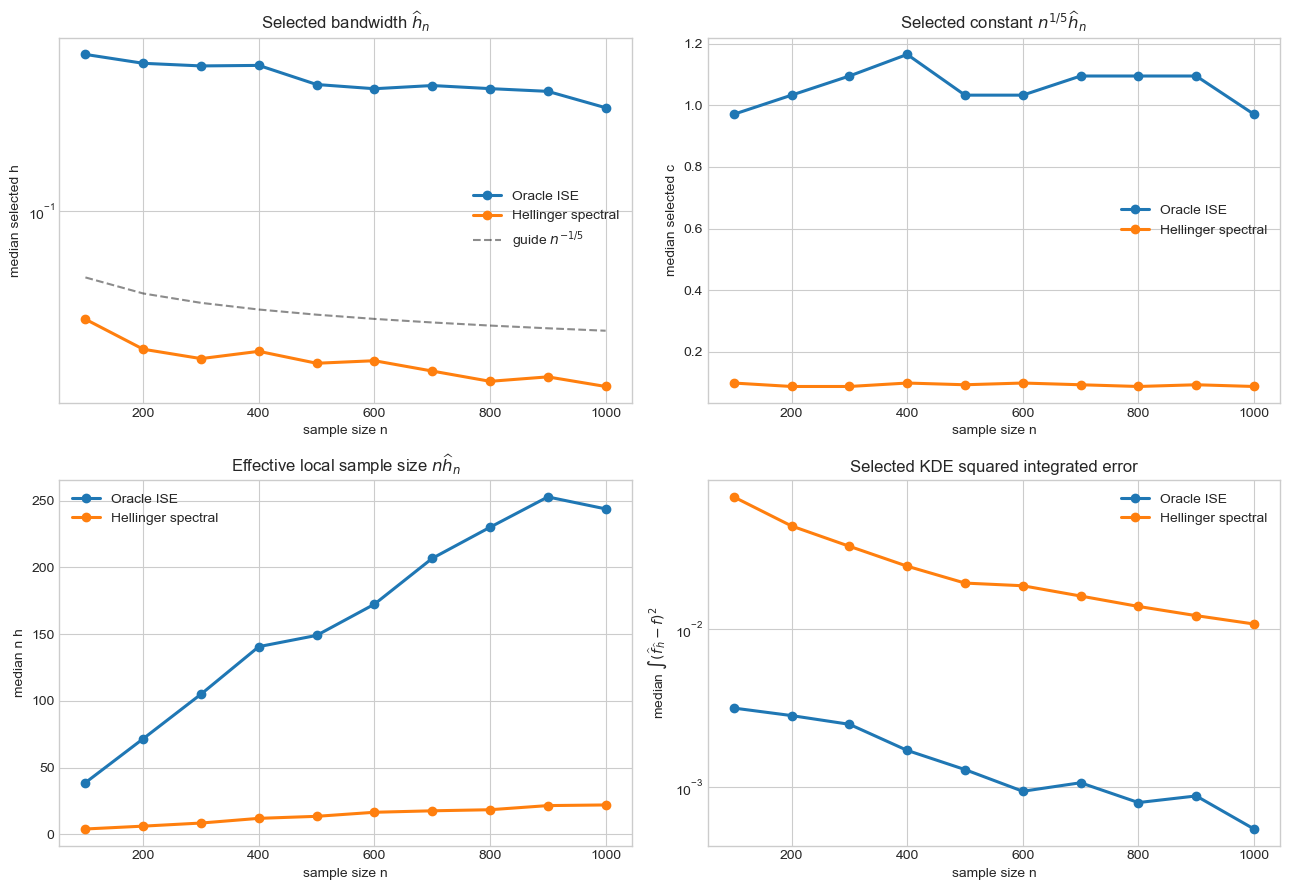

Rate-controlled Hellinger grid
-------------------------------
Grid: h_i^(n) = c_i * n^(-1/5)
c_min = 0.01, c_max = 2
Therefore any selected bandwidth from this grid satisfies h_n -> 0 and n h_n -> infinity.


In [24]:
# Rate-controlled Hellinger experiment.
# The grid has the form h_i^(n) = c_i * n^(-1/5).
# Increase num_simulations_rate_controlled for final figures.
n_values_rate_controlled = np.arange(100, 1001, 100)
num_simulations_rate_controlled = 10
n_h_rate_controlled = 45
m_x_rate_controlled = 1_001
sigma2_rate_controlled = 1.0
seed_rate_controlled = 610_000
c_grid_rate_controlled = np.geomspace(0.01, 2.00, n_h_rate_controlled)


def select_hellinger_on_rate_controlled_grid(
    samples,
    n_current,
    c_grid,
    sigma2=1.0,
    m_x=1_001,
):
    """Oracle and Hellinger spectral selections on h_i = c_i n^{-1/5}."""
    sigma = np.sqrt(sigma2)
    h_grid_local = c_grid * n_current ** (-1 / 5)
    margin = 6.0 * (sigma + np.max(h_grid_local))
    x_grid_local = np.linspace(samples.min() - margin, samples.max() + margin, m_x)
    truth_local = normal_pdf(x_grid_local, sigma2=sigma2)

    kde_values = np.array([
        kde_eval(x_grid_local, samples, h=h_value, kernel="gaussian")
        for h_value in h_grid_local
    ])
    masses = trapz_integral(kde_values, x=x_grid_local, axis=1)
    kde_values = kde_values / masses[:, None]

    ise_values_local = trapz_integral(
        (kde_values - truth_local[None, :]) ** 2,
        x=x_grid_local,
        axis=1,
    )
    oracle_index_local = int(np.argmin(ise_values_local))

    hellinger_matrix = trapz_integral(
        np.sqrt(kde_values[:, None, :] * kde_values[None, :, :]),
        x=x_grid_local,
        axis=2,
    )
    hellinger_matrix = np.clip((hellinger_matrix + hellinger_matrix.T) / 2, 0.0, 1.0)
    np.fill_diagonal(hellinger_matrix, 1.0)

    hellinger_vector = principal_eigenvector_nonnegative(hellinger_matrix)
    hellinger_index_local = int(np.argmax(hellinger_vector))

    return {
        "h_grid": h_grid_local,
        "oracle_index": oracle_index_local,
        "oracle_h": float(h_grid_local[oracle_index_local]),
        "oracle_c": float(c_grid[oracle_index_local]),
        "oracle_error": float(ise_values_local[oracle_index_local]),
        "hellinger_index": hellinger_index_local,
        "hellinger_h": float(h_grid_local[hellinger_index_local]),
        "hellinger_c": float(c_grid[hellinger_index_local]),
        "hellinger_error": float(ise_values_local[hellinger_index_local]),
        "hellinger_vector": hellinger_vector,
    }


rate_controlled_rows = []

for n_current in n_values_rate_controlled:
    for simulation in range(num_simulations_rate_controlled):
        rng = np.random.default_rng(seed_rate_controlled + 10_000 * int(n_current) + simulation)
        samples = rng.normal(0.0, np.sqrt(sigma2_rate_controlled), size=int(n_current))
        result = select_hellinger_on_rate_controlled_grid(
            samples=samples,
            n_current=int(n_current),
            c_grid=c_grid_rate_controlled,
            sigma2=sigma2_rate_controlled,
            m_x=m_x_rate_controlled,
        )
        rate_controlled_rows.append({
            "n": int(n_current),
            "simulation": int(simulation),
            "method": "Oracle ISE",
            "index": result["oracle_index"],
            "h": result["oracle_h"],
            "c": result["oracle_c"],
            "nh": int(n_current) * result["oracle_h"],
            "squared_integrated_error": result["oracle_error"],
        })
        rate_controlled_rows.append({
            "n": int(n_current),
            "simulation": int(simulation),
            "method": "Hellinger spectral",
            "index": result["hellinger_index"],
            "h": result["hellinger_h"],
            "c": result["hellinger_c"],
            "nh": int(n_current) * result["hellinger_h"],
            "squared_integrated_error": result["hellinger_error"],
        })

rate_controlled_results = np.array(rate_controlled_rows, dtype=object)

def rate_controlled_series(method, key, reducer=np.median):
    values = []
    for n_current in n_values_rate_controlled:
        current = [row[key] for row in rate_controlled_rows if row["n"] == int(n_current) and row["method"] == method]
        values.append(reducer(np.asarray(current, dtype=float)))
    return np.asarray(values, dtype=float)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

for method in ["Oracle ISE", "Hellinger spectral"]:
    h_median = rate_controlled_series(method, "h")
    c_median = rate_controlled_series(method, "c")
    nh_median = rate_controlled_series(method, "nh")
    error_median = rate_controlled_series(method, "squared_integrated_error")

    axes[0].plot(n_values_rate_controlled, h_median, marker="o", lw=2.2, label=method)
    axes[1].plot(n_values_rate_controlled, c_median, marker="o", lw=2.2, label=method)
    axes[2].plot(n_values_rate_controlled, nh_median, marker="o", lw=2.2, label=method)
    axes[3].plot(n_values_rate_controlled, error_median, marker="o", lw=2.2, label=method)

guide = c_grid_rate_controlled[len(c_grid_rate_controlled) // 2] * n_values_rate_controlled ** (-1 / 5)
axes[0].plot(n_values_rate_controlled, guide, "k--", alpha=0.45, label=r"guide $n^{-1/5}$")

axes[0].set_title(r"Selected bandwidth $\widehat h_n$")
axes[0].set_xlabel("sample size n")
axes[0].set_ylabel("median selected h")
axes[0].set_yscale("log")

axes[1].set_title(r"Selected constant $n^{1/5}\widehat h_n$")
axes[1].set_xlabel("sample size n")
axes[1].set_ylabel("median selected c")

axes[2].set_title(r"Effective local sample size $n\widehat h_n$")
axes[2].set_xlabel("sample size n")
axes[2].set_ylabel("median n h")

axes[3].set_title("Selected KDE squared integrated error")
axes[3].set_xlabel("sample size n")
axes[3].set_ylabel(r"median $\int(\widehat f_{\widehat h}-f)^2$")
axes[3].set_yscale("log")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

print("Rate-controlled Hellinger grid")
print("-------------------------------")
print(r"Grid: h_i^(n) = c_i * n^(-1/5)")
print(f"c_min = {c_grid_rate_controlled[0]:.6g}, c_max = {c_grid_rate_controlled[-1]:.6g}")
print("Therefore any selected bandwidth from this grid satisfies h_n -> 0 and n h_n -> infinity.")

